# Beijing Multi-Site Air Quality Classification

## 1. Environment Setup and Reproducibility

This cell imports the required libraries, sets random seeds for reproducibility, mounts Google Drive, defines the project paths, and configures the notebook’s visual settings.

In [ ]:

# Setup, Imports, and Reproducibility

import os
import random
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from google.colab import drive

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Request deterministic TensorFlow operations where available
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

# Mount Google Drive
drive.mount("/content/drive")

# Project directories
PROJECT_DIR = Path(
    "/content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality"
)
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
LOG_DIR = PROJECT_DIR / "logs"

# Create output directories if they do not exist
for directory in [
    DATA_DIR,
    MODEL_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    LOG_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

# Plot settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("Setup completed successfully.")
print(f"TensorFlow version: {tf.__version__}")
print(f"Project directory: {PROJECT_DIR}")
print(f"Random seed: {SEED}")

Mounted at /content/drive
Setup completed successfully.
TensorFlow version: 2.21.0
Project directory: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality
Random seed: 42


## 2. Load and Combine the Dataset

The Beijing Multi-Site Air Quality dataset is loaded from Google Drive. The archive contains hourly measurements collected from multiple monitoring stations. All station CSV files are combined into one dataframe while preserving the station identifier.

In [ ]:

# Extract, Load, and Combine Station CSV Files

import glob
import zipfile

ZIP_PATH = DATA_DIR / "beijing+multi+site+air+quality+data.zip"
EXTRACT_DIR = Path("/content/extracted_beijing_data")

# Confirm that the dataset exists
if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"Dataset archive not found:\n{ZIP_PATH}\n\n"
        "Upload the ZIP file to the project's data folder."
    )

# Create the temporary extraction directory
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)


print(f"Extracting: {ZIP_PATH.name}")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

# Extract any ZIP archives contained inside the main archive
nested_zip_files = list(EXTRACT_DIR.rglob("*.zip"))

for nested_zip in nested_zip_files:
    print(f"Extracting nested archive: {nested_zip.name}")

    with zipfile.ZipFile(nested_zip, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

# Locate the station CSV files
csv_files = sorted(EXTRACT_DIR.rglob("PRSA_Data_*.csv"))

if not csv_files:
    raise FileNotFoundError(
        "No PRSA station CSV files were found after extraction."
    )

print(f"\nFound {len(csv_files)} station files:")

for file_path in csv_files:
    print(f" - {file_path.name}")

# Load and combine all station files
station_dataframes = []

for file_path in csv_files:
    station_df = pd.read_csv(file_path)
    station_dataframes.append(station_df)

df_raw = pd.concat(
    station_dataframes,
    ignore_index=True,
)

print("\nRaw dataset loaded successfully.")
print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")
print(f"Duplicate rows: {df_raw.duplicated().sum():,}")

display(df_raw.head())

Extracting: beijing+multi+site+air+quality+data.zip
Extracting nested archive: PRSA2017_Data_20130301-20170228.zip

Found 12 station files:
 - PRSA_Data_Aotizhongxin_20130301-20170228.csv
 - PRSA_Data_Changping_20130301-20170228.csv
 - PRSA_Data_Dingling_20130301-20170228.csv
 - PRSA_Data_Dongsi_20130301-20170228.csv
 - PRSA_Data_Guanyuan_20130301-20170228.csv
 - PRSA_Data_Gucheng_20130301-20170228.csv
 - PRSA_Data_Huairou_20130301-20170228.csv
 - PRSA_Data_Nongzhanguan_20130301-20170228.csv
 - PRSA_Data_Shunyi_20130301-20170228.csv
 - PRSA_Data_Tiantan_20130301-20170228.csv
 - PRSA_Data_Wanliu_20130301-20170228.csv
 - PRSA_Data_Wanshouxigong_20130301-20170228.csv

Raw dataset loaded successfully.
Rows: 420,768
Columns: 18
Duplicate rows: 0


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


## 3. Create the Classification Target

The continuous PM2.5 measurement is converted into four ordered air-quality severity classes. The class names are presented as project-defined grouped concentration bands to avoid incorrectly representing them as the complete official AQI categories.

The original PM2.5 column is retained temporarily for exploratory analysis but will be removed from the model features to prevent direct target leakage.

In [ ]:
#  Data Validation, Timestamp, and Target Creation

# Working on a copy of the raw dataset
df = df_raw.copy()

# Confirm that all required columns are present
required_columns = {
    "year", "month", "day", "hour",
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM", "station"
}

missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {sorted(missing_columns)}"
    )

# Create one timestamp from the separate date and hour columns
df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]],
    errors="coerce",
)

# Remove rows with that has invalid timestamp
invalid_datetime_count = df["datetime"].isna().sum()

if invalid_datetime_count > 0:
    print(
        f"Removing {invalid_datetime_count:,} rows "
        "with invalid timestamps."
    )
    df = df.dropna(subset=["datetime"]).copy()

# Remove rows where the target measurement is missing
missing_target_count = df["PM2.5"].isna().sum()

print(f"Missing PM2.5 values: {missing_target_count:,}")

df = df.dropna(subset=["PM2.5"]).copy()

negative_target_count = (df["PM2.5"] < 0).sum()

if negative_target_count > 0:
    print(
        f"Removing {negative_target_count:,} rows "
        "with negative PM2.5 values."
    )
    df = df[df["PM2.5"] >= 0].copy()

# Sort the observations chronologically
df = df.sort_values(
    ["datetime", "station"]
).reset_index(drop=True)

# Convert PM2.5 into four project-defined severity classes
class_names = ["Low", "Elevated", "High", "Very High"]

df["AirQualityClass"] = pd.cut(
    df["PM2.5"],
    bins=[-np.inf, 35.4, 55.4, 150.4, np.inf],
    labels=[0, 1, 2, 3],
    include_lowest=True,
).astype("int64")

class_labels = {
    0: "Low",
    1: "Elevated",
    2: "High",
    3: "Very High",
}

# Display the resulting class distribution
class_summary = (
    df["AirQualityClass"]
    .value_counts()
    .sort_index()
    .rename_axis("Class")
    .reset_index(name="Count")
)

class_summary["Label"] = class_summary["Class"].map(class_labels)
class_summary["Percentage"] = (
    class_summary["Count"] / len(df) * 100
).round(2)

class_summary = class_summary[
    ["Class", "Label", "Count", "Percentage"]
]

print("\nTarget creation completed.")
print(f"Usable observations: {len(df):,}")
print(
    f"Date range: {df['datetime'].min()} "
    f"to {df['datetime'].max()}"
)

display(class_summary)

Missing PM2.5 values: 8,739

Target creation completed.
Usable observations: 412,029
Date range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,Class,Label,Count,Percentage
0,0,Low,153871,37.34
1,1,Elevated,53248,12.92
2,2,High,142240,34.52
3,3,Very High,62670,15.21


## 4. Data Quality Assessment

This section examines data types, missing values, duplicate station timestamps, and summary statistics. These checks guide later preprocessing decisions and help identify potential measurement or data-quality problems.

In [ ]:
# Data Quality Assessment

print("Dataset shape:", df.shape)
print(f"Total observations: {len(df):,}")
print(f"Total columns: {df.shape[1]}")

duplicate_rows = df.duplicated().sum()

# A station should normally have one observation per timestamp
duplicate_station_times = df.duplicated(
    subset=["station", "datetime"]
).sum()

print(f"\nDuplicate complete rows: {duplicate_rows:,}")
print(
    "Duplicate station-timestamp combinations: "
    f"{duplicate_station_times:,}"
)

# Missing-value summary
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2),
})

missing_summary = (
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing Percentage", ascending=False)
)

print("\nColumns containing missing values:")
display(missing_summary)

# Summary statistics for numerical measurements
measurement_columns = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM",
]

print("\nNumerical summary:")
display(df[measurement_columns].describe().T.round(2))

print("\nColumn data types:")
display(
    df.dtypes.astype(str)
    .rename("Data Type")
    .to_frame()
)

Dataset shape: (412029, 20)
Total observations: 412,029
Total columns: 20

Duplicate complete rows: 0
Duplicate station-timestamp combinations: 0

Columns containing missing values:


,Missing Count,Missing Percentage
CO,15162,3.68
O3,8145,1.98
NO2,6747,1.64
SO2,3698,0.90
wd,1797,0.44
PRES,393,0.10
TEMP,398,0.10
DEWP,403,0.10
RAIN,390,0.09
WSPM,317,0.08



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
PM2.5,412029.0,79.79,80.82,2.00,20.0,55.0,111.0,999.0
PM10,411813.0,104.67,91.72,2.00,36.0,82.0,145.0,999.0
SO2,408331.0,15.84,21.62,0.29,3.0,7.0,20.0,500.0
NO2,405282.0,50.70,35.14,1.03,23.0,43.0,71.0,290.0
CO,396867.0,1231.72,1160.68,100.00,500.0,900.0,1500.0,10000.0
O3,403884.0,57.23,56.60,0.21,11.0,45.0,82.0,1071.0
TEMP,411631.0,13.49,11.44,-19.90,3.1,14.4,23.2,41.6
PRES,411636.0,1010.78,10.47,982.40,1002.3,1010.4,1019.0,1042.8
DEWP,411626.0,2.46,13.80,-43.40,-9.0,3.0,15.1,29.1
RAIN,411639.0,0.06,0.82,0.00,0.0,0.0,0.0,72.5



Column data types:


,Data Type
No,int64
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64


## 5. Exploratory Data Analysis

This section visualizes the target-class distribution and the extent of missing data. The class distribution is moderately imbalanced, so macro-averaged precision, recall, and F1-score will be used alongside accuracy during model evaluation.

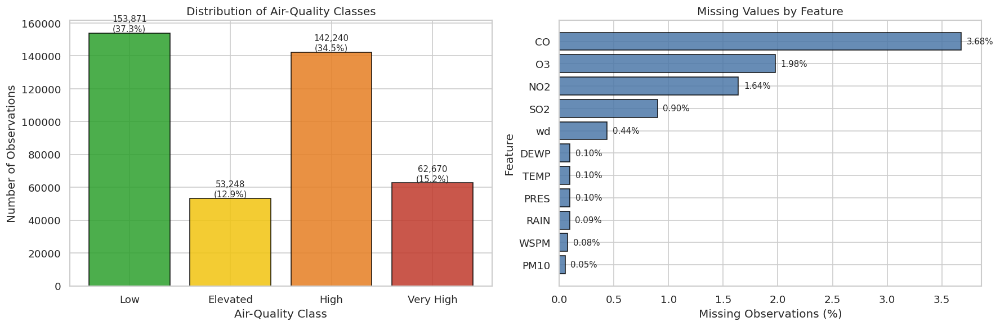

Figure saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/results/figures/class_distribution_and_missingness.png


In [ ]:

# Class Distribution and Missing-Data Visualizations

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Target-class distribution
class_counts = (
    df["AirQualityClass"]
    .value_counts()
    .sort_index()
)

class_colors = [
    "#2ca02c",
    "#f1c40f",
    "#e67e22",
    "#c0392b",
]

bars = axes[0].bar(
    range(len(class_counts)),
    class_counts.values,
    color=class_colors,
    edgecolor="black",
    alpha=0.85,
)

axes[0].set_xticks(range(4))
axes[0].set_xticklabels(
    [class_labels[i] for i in range(4)]
)
axes[0].set_title("Distribution of Air-Quality Classes")
axes[0].set_xlabel("Air-Quality Class")
axes[0].set_ylabel("Number of Observations")

# Add counts and percentages above the bars
for bar, count in zip(bars, class_counts.values):
    percentage = count / len(df) * 100

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9,
    )

# Missing-data percentages
missing_percentages = (
    df.isna().mean()
    .mul(100)
    .loc[lambda values: values > 0]
    .sort_values(ascending=True)
)

axes[1].barh(
    missing_percentages.index,
    missing_percentages.values,
    color="#4c78a8",
    edgecolor="black",
    alpha=0.85,
)

axes[1].set_title("Missing Values by Feature")
axes[1].set_xlabel("Missing Observations (%)")
axes[1].set_ylabel("Feature")

for index, value in enumerate(missing_percentages.values):
    axes[1].text(
        value + 0.05,
        index,
        f"{value:.2f}%",
        va="center",
        fontsize=9,
    )

plt.tight_layout()

# Save a report-ready version
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
figure_path = FIGURES_DIR / "class_distribution_and_missingness.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved to: {figure_path}")

## 6. Correlation Analysis

A correlation matrix is used to examine relationships among pollutant and meteorological measurements. PM2.5 is included only for exploratory analysis. It will be removed from the predictors before model training because the classification target was derived directly from it.

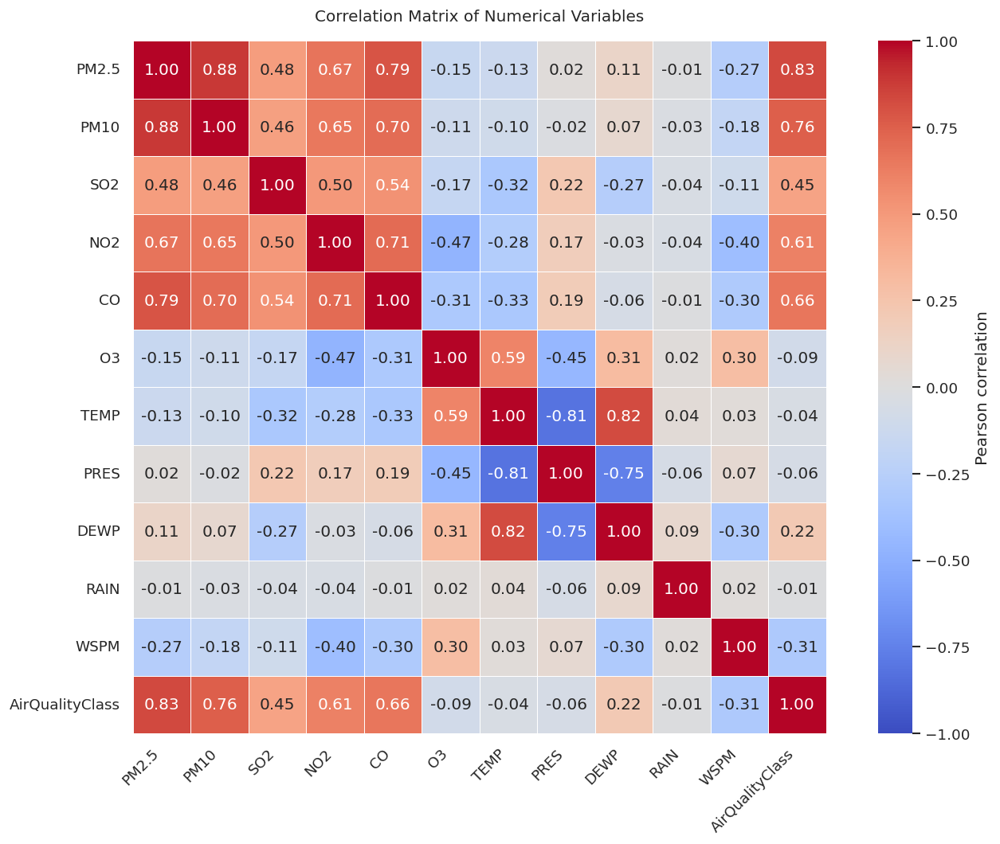

Figure saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/results/figures/numerical_feature_correlation.png


,Correlation with AirQualityClass
PM2.5,0.829282
PM10,0.755564
CO,0.658666
NO2,0.612833
SO2,0.451821
DEWP,0.217525
RAIN,-0.007846
TEMP,-0.039872
PRES,-0.056578
O3,-0.092730


In [ ]:
# Correlation Analysis
correlation_columns = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM",
    "AirQualityClass",
]

correlation_matrix = (
    df[correlation_columns]
    .corr(method="pearson")
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson correlation"},
)

plt.title("Correlation Matrix of Numerical Variables", pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

correlation_figure_path = (
    FIGURES_DIR / "numerical_feature_correlation.png"
)

plt.savefig(
    correlation_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved to: {correlation_figure_path}")

# Display correlations with the target class separately
target_correlations = (
    correlation_matrix["AirQualityClass"]
    .drop("AirQualityClass")
    .sort_values(ascending=False)
    .rename("Correlation with AirQualityClass")
    .to_frame()
)

display(target_correlations)

## 7. Chronological Train, Validation, and Test Split

Because the dataset contains hourly observations, a random split could place future measurements in the training set and earlier measurements in the test set. The data is therefore divided chronologically: the earliest 70% of timestamps form the training set, the following 15% form the validation set, and the most recent 15% form the test set.

All stations recorded at the same timestamp are kept in the same partition. Preprocessing parameters will subsequently be learned from the training partition only.

In [ ]:
# Chronological Train, Validation, and Test Split
# Use unique timestamps so observations recorded at the same

unique_timestamps = np.sort(df["datetime"].unique())

train_cutoff_index = int(len(unique_timestamps) * 0.70)
validation_cutoff_index = int(len(unique_timestamps) * 0.85)

train_cutoff = unique_timestamps[train_cutoff_index - 1]
validation_cutoff = unique_timestamps[validation_cutoff_index - 1]

# Chronological partitions
train_df = df[df["datetime"] <= train_cutoff].copy()

val_df = df[
    (df["datetime"] > train_cutoff)
    & (df["datetime"] <= validation_cutoff)
].copy()

test_df = df[
    df["datetime"] > validation_cutoff
].copy()

# Verify that every observation belongs to exactly one split
assert len(train_df) + len(val_df) + len(test_df) == len(df)

# Verify strict chronological separation
assert train_df["datetime"].max() < val_df["datetime"].min()
assert val_df["datetime"].max() < test_df["datetime"].min()

split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Rows": [
        len(train_df),
        len(val_df),
        len(test_df),
    ],
    "Percentage": [
        len(train_df) / len(df) * 100,
        len(val_df) / len(df) * 100,
        len(test_df) / len(df) * 100,
    ],
    "Start": [
        train_df["datetime"].min(),
        val_df["datetime"].min(),
        test_df["datetime"].min(),
    ],
    "End": [
        train_df["datetime"].max(),
        val_df["datetime"].max(),
        test_df["datetime"].max(),
    ],
})

split_summary["Percentage"] = (
    split_summary["Percentage"].round(2)
)

print("Chronological split completed.")
display(split_summary)

# Compare class distributions across the three partitions
split_class_distribution = pd.concat(
    {
        "Training": train_df["AirQualityClass"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100),

        "Validation": val_df["AirQualityClass"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100),

        "Test": test_df["AirQualityClass"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100),
    },
    axis=1,
).round(2)

split_class_distribution.index = [
    class_labels[class_id]
    for class_id in split_class_distribution.index
]

split_class_distribution.index.name = "Air-Quality Class"

print("\nClass percentages within each split:")
display(split_class_distribution)

Chronological split completed.


,Split,Rows,Percentage,Start,End
0,Training,288258,69.96,2013-03-01 00:00:00,2015-12-18 05:00:00
1,Validation,61785,15.00,2015-12-18 06:00:00,2016-07-24 05:00:00
2,Test,61986,15.04,2016-07-24 06:00:00,2017-02-28 23:00:00



Class percentages within each split:


,Training,Validation,Test
Air-Quality Class,,,
Low,35.86,41.03,40.58
Elevated,13.07,14.52,10.67
High,35.63,33.28,30.61
Very High,15.45,11.17,18.14


## 8. Leakage-Safe Missing-Value Treatment

Missing numerical measurements are replaced using station-specific medians calculated exclusively from the training data. If a station-specific value is unavailable, the overall training median is used. Missing wind directions are filled using each station's most frequent training value.

Binary missingness indicators are also created so the models can learn whether the absence of a measurement contains useful information.

In [ ]:

# Leakage-Safe Missing-Value Treatment


sensor_columns = [
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM",
]

# Calculate all imputation values from training data only
training_global_medians = train_df[sensor_columns].median()

training_station_medians = (
    train_df
    .groupby("station")[sensor_columns]
    .median()
)

# Calculate the most common wind direction for each station
training_station_wind_modes = (
    train_df
    .dropna(subset=["wd"])
    .groupby("station")["wd"]
    .agg(lambda values: values.mode().iloc[0])
)

# Overall training wind-direction mode as a fallback
training_global_wind_mode = (
    train_df["wd"].mode().iloc[0]
)


def impute_missing_values(dataframe):
    """Apply training-derived imputation values to one partition."""

    cleaned = dataframe.copy()

    # Add missingness indicators before filling the values
    for column in sensor_columns:
        cleaned[f"{column}_missing"] = (
            cleaned[column].isna().astype("int8")
        )

        # Use the station-specific training median first
        station_fill_values = cleaned["station"].map(
            training_station_medians[column]
        )

        cleaned[column] = (
            cleaned[column]
            .fillna(station_fill_values)
            .fillna(training_global_medians[column])
        )

    # Add a missingness indicator for wind direction
    cleaned["wd_missing"] = cleaned["wd"].isna().astype("int8")

    station_wind_fill = cleaned["station"].map(
        training_station_wind_modes
    )

    cleaned["wd"] = (
        cleaned["wd"]
        .fillna(station_wind_fill)
        .fillna(training_global_wind_mode)
    )

    return cleaned


# Apply identical training-derived rules to all partitions
train_clean = impute_missing_values(train_df)
val_clean = impute_missing_values(val_df)
test_clean = impute_missing_values(test_df)

# Confirm that no missing predictor values remain
remaining_missing = pd.DataFrame({
    "Training": train_clean[
        sensor_columns + ["wd"]
    ].isna().sum(),

    "Validation": val_clean[
        sensor_columns + ["wd"]
    ].isna().sum(),

    "Test": test_clean[
        sensor_columns + ["wd"]
    ].isna().sum(),
})

print("Remaining missing values after imputation:")
display(remaining_missing)

assert remaining_missing.to_numpy().sum() == 0

print("Missing-value treatment completed successfully.")

Remaining missing values after imputation:


,Training,Validation,Test
PM10,0,0,0
SO2,0,0,0
NO2,0,0,0
CO,0,0,0
O3,0,0,0
TEMP,0,0,0
PRES,0,0,0
DEWP,0,0,0
RAIN,0,0,0
WSPM,0,0,0


Missing-value treatment completed successfully.


## 9. Feature Engineering and Categorical Encoding

Hour, month, and day of the week are cyclical variables. Sine and cosine transformations preserve their circular relationships, such as the similarity between 23:00 and 00:00. Station and wind direction are converted into binary indicator variables.

The original PM2.5 measurement is excluded because the target class was derived directly from it. Including it would create target leakage.

In [ ]:

# Feature Engineering and Categorical Encoding

def engineer_features(dataframe):
    """Create temporal features and encode categorical columns."""

    engineered = dataframe.copy()

    # Cyclical hour encoding
    engineered["hour_sin"] = np.sin(
        2 * np.pi * engineered["hour"] / 24
    )
    engineered["hour_cos"] = np.cos(
        2 * np.pi * engineered["hour"] / 24
    )

    # Cyclical month encoding
    engineered["month_sin"] = np.sin(
        2 * np.pi * (engineered["month"] - 1) / 12
    )
    engineered["month_cos"] = np.cos(
        2 * np.pi * (engineered["month"] - 1) / 12
    )

    # Day-of-week extracted from the timestamp
    engineered["day_of_week"] = (
        engineered["datetime"].dt.dayofweek
    )

    engineered["day_of_week_sin"] = np.sin(
        2 * np.pi * engineered["day_of_week"] / 7
    )
    engineered["day_of_week_cos"] = np.cos(
        2 * np.pi * engineered["day_of_week"] / 7
    )

    # Encode station and wind direction
    engineered = pd.get_dummies(
        engineered,
        columns=["station", "wd"],
        prefix=["station", "wind"],
        dtype="int8",
    )

    return engineered


# Apply feature engineering independently to each partition
train_engineered = engineer_features(train_clean)
val_engineered = engineer_features(val_clean)
test_engineered = engineer_features(test_clean)

target_column = "AirQualityClass"

# Remove identifiers, redundant date columns, the timestamp,
# and PM2.5 because it directly generated the target
columns_to_drop = [
    "No",
    "year",
    "month",
    "day",
    "hour",
    "day_of_week",
    "datetime",
    "PM2.5",
    target_column,
]

X_train = train_engineered.drop(
    columns=columns_to_drop
)
y_train = train_engineered[target_column].astype("int32")

X_val = val_engineered.drop(
    columns=columns_to_drop
)
y_val = val_engineered[target_column].astype("int32")

X_test = test_engineered.drop(
    columns=columns_to_drop
)
y_test = test_engineered[target_column].astype("int32")

# Force validation and test sets to use exactly the training columns
X_val = X_val.reindex(
    columns=X_train.columns,
    fill_value=0,
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0,
)

# Convert all predictors to float32 to reduce memory usage
X_train = X_train.astype("float32")
X_val = X_val.astype("float32")
X_test = X_test.astype("float32")

# Verification checks
assert "PM2.5" not in X_train.columns
assert list(X_train.columns) == list(X_val.columns)
assert list(X_train.columns) == list(X_test.columns)
assert X_train.isna().sum().sum() == 0
assert X_val.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

print("Feature engineering completed.")
print(f"Training features:   {X_train.shape}")
print(f"Validation features: {X_val.shape}")
print(f"Test features:       {X_test.shape}")
print(f"Number of predictor variables: {X_train.shape[1]}")

display(X_train.head())

Feature engineering completed.
Training features:   (288258, 55)
Validation features: (61785, 55)
Test features:       (61986, 55)
Number of predictor variables: 55


,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,...,wind_NNW,wind_NW,wind_S,wind_SE,wind_SSE,wind_SSW,wind_SW,wind_W,wind_WNW,wind_WSW
0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.000000,-18.799999,0.0,4.4,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,6.0,13.0,7.0,300.0,85.0,-2.3,1020.799988,-19.700001,0.0,0.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4.0,3.0,19.0,200.0,82.0,-2.3,1020.799988,-19.700001,0.0,0.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,9.0,3.0,17.0,300.0,89.0,-0.5,1024.500000,-21.400000,0.0,5.7,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4.0,14.0,20.0,300.0,69.0,-0.7,1023.000000,-18.799999,0.0,4.4,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 10. Feature Scaling and Class Weights

Continuous and encoded predictors operate on different numerical scales. A standard scaler is fitted exclusively on the training set and then applied unchanged to the validation and test sets. Scaling is used for Logistic Regression and neural networks, while tree-based models use the unscaled features.

Class weights are calculated from the training target to reduce the influence of class imbalance during model training.

In [ ]:
# Feature Scaling and Class-Weight Calculation
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# Fit the scaler on training predictors only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype("float32")
X_val_scaled = scaler.transform(X_val).astype("float32")
X_test_scaled = scaler.transform(X_test).astype("float32")

# Calculate balanced class weights from training labels only
classes = np.sort(y_train.unique())

class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train,
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        classes,
        class_weight_values,
    )
}

# Verify the scaled arrays
assert X_train_scaled.shape == X_train.shape
assert X_val_scaled.shape == X_val.shape
assert X_test_scaled.shape == X_test.shape

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()
assert np.isfinite(X_test_scaled).all()

print("Feature scaling completed.")
print(f"Training array:   {X_train_scaled.shape}")
print(f"Validation array: {X_val_scaled.shape}")
print(f"Test array:       {X_test_scaled.shape}")

print("\nTraining-set class weights:")

for class_id, weight in class_weights.items():
    print(
        f"Class {class_id} "
        f"({class_labels[class_id]}): {weight:.4f}"
    )

print(
    "\nMean of scaled training features: "
    f"{X_train_scaled.mean():.4f}"
)
print(
    "Standard deviation of scaled training features: "
    f"{X_train_scaled.std():.4f}"
)

Feature scaling completed.
Training array:   (288258, 55)
Validation array: (61785, 55)
Test array:       (61986, 55)

Training-set class weights:
Class 0 (Low): 0.6972
Class 1 (Elevated): 1.9133
Class 2 (High): 0.7017
Class 3 (Very High): 1.6186

Mean of scaled training features: 0.0000
Standard deviation of scaled training features: 1.0000


## 11. Evaluation and Experiment Logging

All experiments are evaluated consistently using accuracy, macro-averaged precision, recall and F1-score, weighted F1-score, and multiclass one-vs-rest ROC-AUC. Macro-F1 is the primary model-selection metric because it gives equal importance to each air-quality class despite class imbalance.

Validation results are used for model comparison. The test set remains untouched until the final models have been selected.

In [ ]:
# Evaluation and Experiment Logging

import json
import time

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
)

experiment_results = []


def evaluate_and_log_experiment(
    experiment_id,
    paradigm,
    model_name,
    hyperparameters,
    y_true,
    y_pred,
    y_prob=None,
    training_time_seconds=None,
    observations="",
):
    """Calculate validation metrics and store one experiment."""

    accuracy = accuracy_score(y_true, y_pred)

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )
    )

    weighted_f1 = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0,
    )[2]

    roc_auc = np.nan

    if y_prob is not None:
        try:
            roc_auc = roc_auc_score(
                y_true,
                y_prob,
                multi_class="ovr",
                average="macro",
            )
        except ValueError as error:
            print(f"ROC-AUC could not be calculated: {error}")

    if isinstance(hyperparameters, dict):
        hyperparameters = json.dumps(
            hyperparameters,
            sort_keys=True,
        )

    result = {
        "Experiment ID": experiment_id,
        "Paradigm": paradigm,
        "Model": model_name,
        "Hyperparameters": hyperparameters,
        "Data Split": (
            "Chronological 70% train / "
            "15% validation / 15% test"
        ),
        "Evaluation Partition": "Validation",
        "Accuracy": round(accuracy, 4),
        "Macro Precision": round(macro_precision, 4),
        "Macro Recall": round(macro_recall, 4),
        "Macro F1": round(macro_f1, 4),
        "Weighted F1": round(weighted_f1, 4),
        "Macro ROC-AUC OVR": (
            round(roc_auc, 4)
            if not np.isnan(roc_auc)
            else np.nan
        ),
        "Training Time (seconds)": (
            round(training_time_seconds, 2)
            if training_time_seconds is not None
            else np.nan
        ),
        "Observations": observations,
    }

    experiment_results.append(result)

    print(f"\n{experiment_id}: {model_name}")
    print(f"Accuracy:          {accuracy:.4f}")
    print(f"Macro precision:   {macro_precision:.4f}")
    print(f"Macro recall:      {macro_recall:.4f}")
    print(f"Macro F1:          {macro_f1:.4f}")
    print(f"Weighted F1:       {weighted_f1:.4f}")

    if not np.isnan(roc_auc):
        print(f"Macro ROC-AUC:     {roc_auc:.4f}")

    if training_time_seconds is not None:
        print(
            "Training time:     "
            f"{training_time_seconds:.2f} seconds"
        )

    return result


print("Experiment logger is ready.")
print("Primary model-selection metric: validation Macro F1")

Experiment logger is ready.
Primary model-selection metric: validation Macro F1


## 12. Traditional Machine-Learning Experiments

### Experiment 1: Baseline Logistic Regression

Logistic Regression provides an interpretable linear baseline. This experiment uses standardized predictors and no class weighting, allowing later experiments to show whether imbalance treatment and nonlinear models improve performance.

In [ ]:

# EXP-01 Baseline Logistic Regression

from sklearn.linear_model import LogisticRegression

# Store trained models and their validation predictions
trained_models = {}
validation_predictions = {}
validation_probabilities = {}

logistic_baseline = LogisticRegression(
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    max_iter=1000,
    class_weight=None,
    random_state=SEED,
)

start_time = time.perf_counter()

logistic_baseline.fit(
    X_train_scaled,
    y_train,
)

training_time = time.perf_counter() - start_time

# Validation predictions
y_val_pred_lr_baseline = logistic_baseline.predict(
    X_val_scaled
)

y_val_prob_lr_baseline = logistic_baseline.predict_proba(
    X_val_scaled
)

# Save the model and predictions for later comparison
trained_models["EXP-01"] = logistic_baseline
validation_predictions["EXP-01"] = y_val_pred_lr_baseline
validation_probabilities["EXP-01"] = y_val_prob_lr_baseline

# Evaluate and log the experiment
evaluate_and_log_experiment(
    experiment_id="EXP-01",
    paradigm="Traditional ML",
    model_name="Logistic Regression Baseline",
    hyperparameters={
        "C": 1.0,
        "penalty": "l2",
        "solver": "lbfgs",
        "max_iter": 1000,
        "class_weight": None,
        "scaled_features": True,
    },
    y_true=y_val,
    y_pred=y_val_pred_lr_baseline,
    y_prob=y_val_prob_lr_baseline,
    training_time_seconds=training_time,
    observations=(
        "Linear baseline without class weighting; "
        "used as the reference for later experiments."
    ),
)


EXP-01: Logistic Regression Baseline
Accuracy:          0.7917
Macro precision:   0.7507
Macro recall:      0.6957
Macro F1:          0.7076
Weighted F1:       0.7702
Macro ROC-AUC:     0.9367
Training time:     2.10 seconds


{'Experiment ID': 'EXP-01',
 'Paradigm': 'Traditional ML',
 'Model': 'Logistic Regression Baseline',
 'Hyperparameters': '{"C": 1.0, "class_weight": null, "max_iter": 1000, "penalty": "l2", "scaled_features": true, "solver": "lbfgs"}',
 'Data Split': 'Chronological 70% train / 15% validation / 15% test',
 'Evaluation Partition': 'Validation',
 'Accuracy': 0.7917,
 'Macro Precision': 0.7507,
 'Macro Recall': 0.6957,
 'Macro F1': 0.7076,
 'Weighted F1': 0.7702,
 'Macro ROC-AUC OVR': np.float64(0.9367),
 'Training Time (seconds)': 2.1,
 'Observations': 'Linear baseline without class weighting; used as the reference for later experiments.'}

### Experiment 2: Class-Weighted Logistic Regression

This experiment applies training-derived class weights to give greater importance to underrepresented classes. Compared with the baseline, class weighting is expected to improve minority-class recall and macro-F1, although overall accuracy may decrease.

In [ ]:

# EXP-02 Class-Weighted Logistic Regression

logistic_weighted = LogisticRegression(
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    max_iter=1000,
    class_weight=class_weights,
    random_state=SEED,
)

start_time = time.perf_counter()

logistic_weighted.fit(
    X_train_scaled,
    y_train,
)

training_time = time.perf_counter() - start_time

# Validation predictions
y_val_pred_lr_weighted = logistic_weighted.predict(
    X_val_scaled
)

y_val_prob_lr_weighted = logistic_weighted.predict_proba(
    X_val_scaled
)

# Save the model and validation outputs
trained_models["EXP-02"] = logistic_weighted
validation_predictions["EXP-02"] = y_val_pred_lr_weighted
validation_probabilities["EXP-02"] = y_val_prob_lr_weighted

# Evaluate and log the experiment
evaluate_and_log_experiment(
    experiment_id="EXP-02",
    paradigm="Traditional ML",
    model_name="Class-Weighted Logistic Regression",
    hyperparameters={
        "C": 1.0,
        "penalty": "l2",
        "solver": "lbfgs",
        "max_iter": 1000,
        "class_weight": "balanced training-derived weights",
        "scaled_features": True,
    },
    y_true=y_val,
    y_pred=y_val_pred_lr_weighted,
    y_prob=y_val_prob_lr_weighted,
    training_time_seconds=training_time,
    observations=(
        "Tests whether class weighting improves macro recall "
        "and macro F1 relative to the unweighted baseline."
    ),
)


EXP-02: Class-Weighted Logistic Regression
Accuracy:          0.7592
Macro precision:   0.7555
Macro recall:      0.7652
Macro F1:          0.7406
Weighted F1:       0.7727
Macro ROC-AUC:     0.9376
Training time:     2.59 seconds


{'Experiment ID': 'EXP-02',
 'Paradigm': 'Traditional ML',
 'Model': 'Class-Weighted Logistic Regression',
 'Hyperparameters': '{"C": 1.0, "class_weight": "balanced training-derived weights", "max_iter": 1000, "penalty": "l2", "scaled_features": true, "solver": "lbfgs"}',
 'Data Split': 'Chronological 70% train / 15% validation / 15% test',
 'Evaluation Partition': 'Validation',
 'Accuracy': 0.7592,
 'Macro Precision': 0.7555,
 'Macro Recall': 0.7652,
 'Macro F1': 0.7406,
 'Weighted F1': 0.7727,
 'Macro ROC-AUC OVR': np.float64(0.9376),
 'Training Time (seconds)': 2.59,
 'Observations': 'Tests whether class weighting improves macro recall and macro F1 relative to the unweighted baseline.'}

### Experiment 3: Baseline Random Forest

Random Forest can model nonlinear relationships and interactions among pollutants, weather conditions, time features, and monitoring stations. Unlike Logistic Regression, it does not require feature scaling. This baseline uses default tree depth and no class weighting.

In [ ]:

# EXP-03 Baseline Random Forest

from sklearn.ensemble import RandomForestClassifier

random_forest_baseline = RandomForestClassifier(
    n_estimators=150,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight=None,
    random_state=SEED,
    n_jobs=-1,
)

start_time = time.perf_counter()

# Tree models use the unscaled feature matrices
random_forest_baseline.fit(
    X_train,
    y_train,
)

training_time = time.perf_counter() - start_time

# Validation predictions
y_val_pred_rf_baseline = random_forest_baseline.predict(
    X_val
)

y_val_prob_rf_baseline = random_forest_baseline.predict_proba(
    X_val
)

# Save the model and validation outputs
trained_models["EXP-03"] = random_forest_baseline
validation_predictions["EXP-03"] = y_val_pred_rf_baseline
validation_probabilities["EXP-03"] = y_val_prob_rf_baseline

# Evaluate and log the experiment
evaluate_and_log_experiment(
    experiment_id="EXP-03",
    paradigm="Traditional ML",
    model_name="Random Forest Baseline",
    hyperparameters={
        "n_estimators": 150,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": "sqrt",
        "class_weight": None,
        "scaled_features": False,
    },
    y_true=y_val,
    y_pred=y_val_pred_rf_baseline,
    y_prob=y_val_prob_rf_baseline,
    training_time_seconds=training_time,
    observations=(
        "Tests whether nonlinear feature interactions improve "
        "performance beyond the linear Logistic Regression models."
    ),
)


EXP-03: Random Forest Baseline
Accuracy:          0.8260
Macro precision:   0.8073
Macro recall:      0.7456
Macro F1:          0.7642
Weighted F1:       0.8129
Macro ROC-AUC:     0.9601
Training time:     2.03 seconds


{'Experiment ID': 'EXP-03',
 'Paradigm': 'Traditional ML',
 'Model': 'Random Forest Baseline',
 'Hyperparameters': '{"class_weight": null, "max_depth": null, "max_features": "sqrt", "min_samples_leaf": 1, "min_samples_split": 2, "n_estimators": 150, "scaled_features": false}',
 'Data Split': 'Chronological 70% train / 15% validation / 15% test',
 'Evaluation Partition': 'Validation',
 'Accuracy': 0.826,
 'Macro Precision': 0.8073,
 'Macro Recall': 0.7456,
 'Macro F1': 0.7642,
 'Weighted F1': 0.8129,
 'Macro ROC-AUC OVR': np.float64(0.9601),
 'Training Time (seconds)': 2.03,
 'Observations': 'Tests whether nonlinear feature interactions improve performance beyond the linear Logistic Regression models.'}

### Experiment 4: Regularized and Class-Weighted Random Forest

This experiment increases the number of trees, limits tree depth, requires more observations in each leaf, and applies balanced weights within each bootstrap sample. These changes aim to reduce overfitting and improve minority-class recall while retaining the Random Forest's nonlinear modeling ability.

In [ ]:

#  EXP-04 Tuned Random Forest

random_forest_tuned = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1,
)

start_time = time.perf_counter()

random_forest_tuned.fit(
    X_train,
    y_train,
)

training_time = time.perf_counter() - start_time

# Validation predictions
y_val_pred_rf_tuned = random_forest_tuned.predict(
    X_val
)

y_val_prob_rf_tuned = random_forest_tuned.predict_proba(
    X_val
)

# Save the model and validation outputs
trained_models["EXP-04"] = random_forest_tuned
validation_predictions["EXP-04"] = y_val_pred_rf_tuned
validation_probabilities["EXP-04"] = y_val_prob_rf_tuned

# Evaluate and log the experiment
evaluate_and_log_experiment(
    experiment_id="EXP-04",
    paradigm="Traditional ML",
    model_name="Regularized Class-Weighted Random Forest",
    hyperparameters={
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "class_weight": "balanced_subsample",
        "scaled_features": False,
    },
    y_true=y_val,
    y_pred=y_val_pred_rf_tuned,
    y_prob=y_val_prob_rf_tuned,
    training_time_seconds=training_time,
    observations=(
        "Tests regularization and bootstrap-specific class "
        "weighting against the unrestricted forest baseline."
    ),
)


EXP-04: Regularized Class-Weighted Random Forest
Accuracy:          0.8244
Macro precision:   0.7985
Macro recall:      0.8015
Macro F1:          0.7974
Weighted F1:       0.8289
Macro ROC-AUC:     0.9590
Training time:     6.16 seconds


{'Experiment ID': 'EXP-04',
 'Paradigm': 'Traditional ML',
 'Model': 'Regularized Class-Weighted Random Forest',
 'Hyperparameters': '{"class_weight": "balanced_subsample", "max_depth": 20, "max_features": "sqrt", "min_samples_leaf": 2, "min_samples_split": 5, "n_estimators": 300, "scaled_features": false}',
 'Data Split': 'Chronological 70% train / 15% validation / 15% test',
 'Evaluation Partition': 'Validation',
 'Accuracy': 0.8244,
 'Macro Precision': 0.7985,
 'Macro Recall': 0.8015,
 'Macro F1': 0.7974,
 'Weighted F1': 0.8289,
 'Macro ROC-AUC OVR': np.float64(0.959),
 'Training Time (seconds)': 6.16,
 'Observations': 'Tests regularization and bootstrap-specific class weighting against the unrestricted forest baseline.'}

### Experiment 5: Histogram Gradient Boosting

Histogram Gradient Boosting builds trees sequentially, with each tree correcting errors made by earlier trees. This provides a useful comparison with Random Forest, whose trees are trained independently. Balanced class weights and L2 regularization are applied, while internal early stopping is disabled to avoid creating an uncontrolled random validation split.

In [ ]:

#  EXP-05 Histogram Gradient Boosting

from sklearn.ensemble import HistGradientBoostingClassifier

hist_gradient_boosting = HistGradientBoostingClassifier(
    learning_rate=0.08,
    max_iter=200,
    max_leaf_nodes=31,
    max_depth=None,
    min_samples_leaf=30,
    l2_regularization=1.0,
    class_weight="balanced",
    early_stopping=False,
    random_state=SEED,
)

start_time = time.perf_counter()

hist_gradient_boosting.fit(
    X_train,
    y_train,
)

training_time = time.perf_counter() - start_time

# Validation predictions
y_val_pred_hgb = hist_gradient_boosting.predict(
    X_val
)

y_val_prob_hgb = hist_gradient_boosting.predict_proba(
    X_val
)

# Save the model and validation outputs
trained_models["EXP-05"] = hist_gradient_boosting
validation_predictions["EXP-05"] = y_val_pred_hgb
validation_probabilities["EXP-05"] = y_val_prob_hgb

# Evaluate and log the experiment
evaluate_and_log_experiment(
    experiment_id="EXP-05",
    paradigm="Traditional ML",
    model_name="Histogram Gradient Boosting",
    hyperparameters={
        "learning_rate": 0.08,
        "max_iter": 200,
        "max_leaf_nodes": 31,
        "max_depth": None,
        "min_samples_leaf": 30,
        "l2_regularization": 1.0,
        "class_weight": "balanced",
        "early_stopping": False,
        "scaled_features": False,
    },
    y_true=y_val,
    y_pred=y_val_pred_hgb,
    y_prob=y_val_prob_hgb,
    training_time_seconds=training_time,
    observations=(
        "Compares sequential boosting with the independently "
        "trained trees used by Random Forest."
    ),
)


EXP-05: Histogram Gradient Boosting
Accuracy:          0.8233
Macro precision:   0.8025
Macro recall:      0.8240
Macro F1:          0.8041
Weighted F1:       0.8321
Macro ROC-AUC:     0.9646
Training time:     6.19 seconds


{'Experiment ID': 'EXP-05',
 'Paradigm': 'Traditional ML',
 'Model': 'Histogram Gradient Boosting',
 'Hyperparameters': '{"class_weight": "balanced", "early_stopping": false, "l2_regularization": 1.0, "learning_rate": 0.08, "max_depth": null, "max_iter": 200, "max_leaf_nodes": 31, "min_samples_leaf": 30, "scaled_features": false}',
 'Data Split': 'Chronological 70% train / 15% validation / 15% test',
 'Evaluation Partition': 'Validation',
 'Accuracy': 0.8233,
 'Macro Precision': 0.8025,
 'Macro Recall': 0.824,
 'Macro F1': 0.8041,
 'Weighted F1': 0.8321,
 'Macro ROC-AUC OVR': np.float64(0.9646),
 'Training Time (seconds)': 6.19,
 'Observations': 'Compares sequential boosting with the independently trained trees used by Random Forest.'}

## 13. Deep-Learning Input Pipeline

The standardized feature arrays are converted into TensorFlow datasets using the `tf.data` API. Training observations are shuffled with a fixed seed, while validation and test observations retain their chronological order. Batching and prefetching improve training efficiency.

Each neural-network experiment will write its training metrics and model graph to a separate TensorBoard directory in Google Drive.

In [ ]:

# TensorFlow tf.data Input Pipeline


from datetime import datetime

BATCH_SIZE = 512
NUM_CLASSES = len(classes)
INPUT_DIM = X_train_scaled.shape[1]

# Convert target Series to NumPy arrays
y_train_array = y_train.to_numpy(dtype="int32")
y_val_array = y_val.to_numpy(dtype="int32")
y_test_array = y_test.to_numpy(dtype="int32")

# Ensure deterministic tf.data behavior
dataset_options = tf.data.Options()
dataset_options.experimental_deterministic = True

train_dataset = (
    tf.data.Dataset
    .from_tensor_slices(
        (X_train_scaled, y_train_array)
    )
    .shuffle(
        buffer_size=min(len(X_train_scaled), 100_000),
        seed=SEED,
        reshuffle_each_iteration=True,
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    .with_options(dataset_options)
)

validation_dataset = (
    tf.data.Dataset
    .from_tensor_slices(
        (X_val_scaled, y_val_array)
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    .with_options(dataset_options)
)

test_dataset = (
    tf.data.Dataset
    .from_tensor_slices(
        (X_test_scaled, y_test_array)
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    .with_options(dataset_options)
)

# Ensure the TensorBoard root directory exists
LOG_DIR.mkdir(parents=True, exist_ok=True)

# Store neural models and histories separately
deep_models = {}
training_histories = {}
tensorboard_log_paths = {}

print("TensorFlow input pipeline created.")
print(f"Input features: {INPUT_DIM}")
print(f"Output classes: {NUM_CLASSES}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_dataset)}")
print(f"Validation batches: {len(validation_dataset)}")
print(f"Test batches: {len(test_dataset)}")
print(f"TensorBoard root: {LOG_DIR}")

TensorFlow input pipeline created.
Input features: 55
Output classes: 4
Batch size: 512
Training batches: 564
Validation batches: 121
Test batches: 122
TensorBoard root: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/logs


### Experiment 6: Baseline Multilayer Perceptron

The first deep-learning experiment uses a basic multilayer perceptron with two hidden layers and ReLU activation. It establishes a neural-network baseline without dropout, batch normalization, class weighting, or learning-rate scheduling. Training and validation metrics are recorded in TensorBoard.

In [ ]:

#  EXP-06 Baseline Multilayer Perceptron

from tensorflow.keras.callbacks import TensorBoard
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Sequential

# Clear previous TensorFlow model state
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

# Create a unique TensorBoard directory for this run
run_timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
exp06_log_dir = LOG_DIR / "EXP-06" / run_timestamp
exp06_log_dir.mkdir(parents=True, exist_ok=True)

tensorboard_exp06 = TensorBoard(
    log_dir=str(exp06_log_dir),
    histogram_freq=1,
    write_graph=True,
    update_freq="epoch",
    profile_batch=0,
)

# Define the baseline neural network
model_exp06 = Sequential(
    [
        Input(shape=(INPUT_DIM,), name="input_features"),
        Dense(128, activation="relu", name="hidden_1"),
        Dense(64, activation="relu", name="hidden_2"),
        Dense(
            NUM_CLASSES,
            activation="softmax",
            name="class_output",
        ),
    ],
    name="EXP_06_Baseline_MLP",
)

model_exp06.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model_exp06.summary()

start_time = time.perf_counter()

history_exp06 = model_exp06.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20,
    callbacks=[tensorboard_exp06],
    verbose=1,
)

training_time = time.perf_counter() - start_time

# Generate validation predictions
y_val_prob_exp06 = model_exp06.predict(
    validation_dataset,
    verbose=0,
)

y_val_pred_exp06 = np.argmax(
    y_val_prob_exp06,
    axis=1,
)

# Store model, history, predictions, and TensorBoard location
deep_models["EXP-06"] = model_exp06
training_histories["EXP-06"] = history_exp06
tensorboard_log_paths["EXP-06"] = str(exp06_log_dir)

validation_predictions["EXP-06"] = y_val_pred_exp06
validation_probabilities["EXP-06"] = y_val_prob_exp06

# Evaluate and log the experiment
evaluate_and_log_experiment(
    experiment_id="EXP-06",
    paradigm="Deep Learning",
    model_name="Baseline MLP",
    hyperparameters={
        "architecture": "128-64-4",
        "hidden_activation": "relu",
        "output_activation": "softmax",
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "batch_size": BATCH_SIZE,
        "epochs": 20,
        "class_weight": None,
        "dropout": None,
        "batch_normalization": False,
    },
    y_true=y_val_array,
    y_pred=y_val_pred_exp06,
    y_prob=y_val_prob_exp06,
    training_time_seconds=training_time,
    observations=(
        "Neural baseline without regularization or class "
        "weighting; TensorBoard records every epoch."
    ),
)

print(f"\nTensorBoard logs saved to: {exp06_log_dir}")

Model: "EXP_06_Baseline_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 128)            │         7,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_output (Dense)            │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,684 (61.27 KB)

 Trainable params: 15,684 (61.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 31s 2ms/step - accuracy: 0.7638 - loss: 0.5739 - val_accuracy: 0.8109 - val_loss: 0.4524
Epoch 2/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8088 - loss: 0.4593 - val_accuracy: 0.8249 - val_loss: 0.4224
Epoch 3/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8173 - loss: 0.4392 - val_accuracy: 0.8294 - val_loss: 0.4080
Epoch 4/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8223 - loss: 0.4281 - val_accuracy: 0.8267 - val_loss: 0.4117
Epoch 5/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8267 - loss: 0.4173 - val_accuracy: 0.8287 - val_loss: 0.4038
Epoch 6/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8303 - loss: 0.4093 - val_accuracy: 0.8271 - val_loss: 0.4054
Epoch 7/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8327 - loss: 0.4037 - val_accuracy: 0.8336 - val_loss: 0.3983
Epoch 8/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8352 - loss: 0.3977 - val_accuracy: 0

### Experiment 7: Regularized Class-Weighted Neural Network

The baseline MLP showed mild overfitting because training performance continued improving while validation loss plateaued. This experiment introduces batch normalization, dropout, L2 weight regularization, and early stopping. Training-derived class weights are also applied to improve minority-class recognition.

In [ ]:
# EXP-07 Regularized Class-Weighted DNN

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import BatchNormalization, Dropout
from tensorflow.keras.regularizers import l2

tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

# Separate TensorBoard directory for EXP-07
run_timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
exp07_log_dir = LOG_DIR / "EXP-07" / run_timestamp
exp07_log_dir.mkdir(parents=True, exist_ok=True)

tensorboard_exp07 = TensorBoard(
    log_dir=str(exp07_log_dir),
    histogram_freq=1,
    write_graph=True,
    update_freq="epoch",
    profile_batch=0,
)

early_stopping_exp07 = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=5,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1,
)

model_exp07 = Sequential(
    [
        Input(shape=(INPUT_DIM,), name="input_features"),

        Dense(
            256,
            kernel_regularizer=l2(0.0001),
            name="dense_1",
        ),
        BatchNormalization(name="batch_norm_1"),
        tf.keras.layers.Activation("relu"),
        Dropout(0.30, name="dropout_1"),

        Dense(
            128,
            kernel_regularizer=l2(0.0001),
            name="dense_2",
        ),
        BatchNormalization(name="batch_norm_2"),
        tf.keras.layers.Activation("relu"),
        Dropout(0.30, name="dropout_2"),

        Dense(
            64,
            kernel_regularizer=l2(0.0001),
            name="dense_3",
        ),
        BatchNormalization(name="batch_norm_3"),
        tf.keras.layers.Activation("relu"),

        Dense(
            NUM_CLASSES,
            activation="softmax",
            name="class_output",
        ),
    ],
    name="EXP_07_Regularized_DNN",
)

model_exp07.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model_exp07.summary()

start_time = time.perf_counter()

history_exp07 = model_exp07.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=40,
    class_weight=class_weights,
    callbacks=[
        tensorboard_exp07,
        early_stopping_exp07,
    ],
    verbose=1,
)

training_time = time.perf_counter() - start_time

# Validation predictions
y_val_prob_exp07 = model_exp07.predict(
    validation_dataset,
    verbose=0,
)

y_val_pred_exp07 = np.argmax(
    y_val_prob_exp07,
    axis=1,
)

# Store outputs
deep_models["EXP-07"] = model_exp07
training_histories["EXP-07"] = history_exp07
tensorboard_log_paths["EXP-07"] = str(exp07_log_dir)

validation_predictions["EXP-07"] = y_val_pred_exp07
validation_probabilities["EXP-07"] = y_val_prob_exp07

# Log experiment
evaluate_and_log_experiment(
    experiment_id="EXP-07",
    paradigm="Deep Learning",
    model_name="Regularized Class-Weighted DNN",
    hyperparameters={
        "architecture": "256-128-64-4",
        "hidden_activation": "relu",
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "batch_size": BATCH_SIZE,
        "maximum_epochs": 40,
        "class_weight": "balanced training-derived weights",
        "dropout": 0.30,
        "batch_normalization": True,
        "l2_regularization": 0.0001,
        "early_stopping_patience": 5,
    },
    y_true=y_val_array,
    y_pred=y_val_pred_exp07,
    y_prob=y_val_prob_exp07,
    training_time_seconds=training_time,
    observations=(
        "Adds class weighting and multiple regularization "
        "methods to address imbalance and baseline overfitting."
    ),
)

print(
    "\nEpochs completed:",
    len(history_exp07.history["loss"]),
)
print(f"TensorBoard logs saved to: {exp07_log_dir}")

Model: "EXP_07_Regularized_DNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 256)            │        14,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_3                    │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_output (Dense)            │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,540 (224.77 KB)

 Trainable params: 56,644 (221.27 KB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/40
564/564 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6994 - loss: 0.7037 - val_accuracy: 0.7865 - val_loss: 0.5258
Epoch 2/40
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7572 - loss: 0.5730 - val_accuracy: 0.7975 - val_loss: 0.4921
Epoch 3/40
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7677 - loss: 0.5474 - val_accuracy: 0.8009 - val_loss: 0.4759
Epoch 4/40
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7749 - loss: 0.5308 - val_accuracy: 0.8019 - val_loss: 0.4703
Epoch 5/40
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7782 - loss: 0.5209 - val_accuracy: 0.8053 - val_loss: 0.4587
Epoch 6/40
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7815 - loss: 0.5126 - val_accuracy: 0.8062 - val_loss: 0.4586
Epoch 7/40
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7832 - loss: 0.5103 - val_accuracy: 0.8129 - val_loss: 0.4465
Epoch 8/40
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7837 - loss: 0.5069 - val_accuracy: 0.

### Experiment 8: Optimized Neural Network with Learning-Rate Scheduling

This experiment replaces ReLU with the smoother Swish activation, reduces dropout from 0.30 to 0.20, starts with a higher learning rate, and reduces that rate when validation loss stops improving. Early stopping and TensorBoard logging are retained. The experiment tests whether adaptive optimization improves convergence and generalization.

In [ ]:

#  EXP-08 Optimized DNN with LR Scheduling

from tensorflow.keras.callbacks import ReduceLROnPlateau

tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

# Separate TensorBoard directory for EXP-08
run_timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
exp08_log_dir = LOG_DIR / "EXP-08" / run_timestamp
exp08_log_dir.mkdir(parents=True, exist_ok=True)

tensorboard_exp08 = TensorBoard(
    log_dir=str(exp08_log_dir),
    histogram_freq=1,
    write_graph=True,
    update_freq="epoch",
    profile_batch=0,
)

early_stopping_exp08 = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=6,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1,
)

reduce_lr_exp08 = ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=2,
    min_delta=0.001,
    min_lr=0.00001,
    verbose=1,
)

model_exp08 = Sequential(
    [
        Input(shape=(INPUT_DIM,), name="input_features"),

        Dense(
            256,
            activation="swish",
            kernel_regularizer=l2(0.00005),
            name="dense_1",
        ),
        BatchNormalization(name="batch_norm_1"),
        Dropout(0.20, name="dropout_1"),

        Dense(
            128,
            activation="swish",
            kernel_regularizer=l2(0.00005),
            name="dense_2",
        ),
        BatchNormalization(name="batch_norm_2"),
        Dropout(0.20, name="dropout_2"),

        Dense(
            64,
            activation="swish",
            kernel_regularizer=l2(0.00005),
            name="dense_3",
        ),

        Dense(
            NUM_CLASSES,
            activation="softmax",
            name="class_output",
        ),
    ],
    name="EXP_08_Optimized_DNN",
)

model_exp08.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.002
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model_exp08.summary()

start_time = time.perf_counter()

history_exp08 = model_exp08.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=50,
    class_weight=class_weights,
    callbacks=[
        tensorboard_exp08,
        reduce_lr_exp08,
        early_stopping_exp08,
    ],
    verbose=1,
)

training_time = time.perf_counter() - start_time

# Validation predictions
y_val_prob_exp08 = model_exp08.predict(
    validation_dataset,
    verbose=0,
)

y_val_pred_exp08 = np.argmax(
    y_val_prob_exp08,
    axis=1,
)

# Store outputs
deep_models["EXP-08"] = model_exp08
training_histories["EXP-08"] = history_exp08
tensorboard_log_paths["EXP-08"] = str(exp08_log_dir)

validation_predictions["EXP-08"] = y_val_pred_exp08
validation_probabilities["EXP-08"] = y_val_prob_exp08

# Log experiment
evaluate_and_log_experiment(
    experiment_id="EXP-08",
    paradigm="Deep Learning",
    model_name="Optimized DNN with LR Scheduling",
    hyperparameters={
        "architecture": "256-128-64-4",
        "hidden_activation": "swish",
        "optimizer": "Adam",
        "initial_learning_rate": 0.002,
        "batch_size": BATCH_SIZE,
        "maximum_epochs": 50,
        "class_weight": "balanced training-derived weights",
        "dropout": 0.20,
        "batch_normalization": True,
        "l2_regularization": 0.00005,
        "reduce_lr_factor": 0.5,
        "reduce_lr_patience": 2,
        "early_stopping_patience": 6,
    },
    y_true=y_val_array,
    y_pred=y_val_pred_exp08,
    y_prob=y_val_prob_exp08,
    training_time_seconds=training_time,
    observations=(
        "Tests Swish activation, lower dropout, and adaptive "
        "learning-rate reduction against EXP-07."
    ),
)

print(
    "\nEpochs completed:",
    len(history_exp08.history["loss"]),
)
print(f"TensorBoard logs saved to: {exp08_log_dir}")

Model: "EXP_08_Optimized_DNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 256)            │        14,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_output (Dense)            │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,284 (223.77 KB)

 Trainable params: 56,516 (220.77 KB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/50
564/564 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7416 - loss: 0.5944 - val_accuracy: 0.7990 - val_loss: 0.4713 - learning_rate: 0.0020
Epoch 2/50
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7740 - loss: 0.5252 - val_accuracy: 0.8180 - val_loss: 0.4373 - learning_rate: 0.0020
Epoch 3/50
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7812 - loss: 0.5089 - val_accuracy: 0.8126 - val_loss: 0.4473 - learning_rate: 0.0020
Epoch 4/50
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7860 - loss: 0.5005 - val_accuracy: 0.8163 - val_loss: 0.4354 - learning_rate: 0.0020
Epoch 5/50
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7908 - loss: 0.4907 - val_accuracy: 0.8082 - val_loss: 0.4540 - learning_rate: 0.0020
Epoch 6/50
560/564 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7776 - loss: 0.5277
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0010000000474974513.
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7934 - loss: 0.4883 - v

## 14. Experiment Comparison and Model Selection

Eight experiments were conducted across traditional machine-learning and deep-learning paradigms. Models are ranked primarily by validation macro-F1 because this metric gives equal importance to all four classes. Accuracy, macro recall, weighted F1, ROC-AUC, and training time provide additional evidence for model selection.

In [ ]:

#  Experiment Results Table

# Replace notes with evidence-based observations
result_observations = {
    "EXP-01": (
        "Strong accuracy but lower macro recall showed that the "
        "unweighted linear model favored more frequent classes."
    ),
    "EXP-02": (
        "Class weighting increased macro F1 from 0.7076 to "
        "0.7406 and macro recall from 0.6957 to 0.7652, "
        "although accuracy decreased."
    ),
    "EXP-03": (
        "Nonlinear Random Forest improved accuracy and macro F1 "
        "over both Logistic Regression configurations."
    ),
    "EXP-04": (
        "Regularization and balanced bootstrap weights increased "
        "macro F1 from 0.7642 to 0.7974 and substantially "
        "improved macro recall."
    ),
    "EXP-05": (
        "Sequential boosting produced the strongest traditional "
        "result, with macro F1 of 0.8041 and ROC-AUC of 0.9646."
    ),
    "EXP-06": (
        "The baseline MLP achieved high accuracy, but validation "
        "loss plateaued while training accuracy continued rising, "
        "indicating mild overfitting."
    ),
    "EXP-07": (
        "Class weighting and regularization improved macro recall "
        "to 0.8272. Early stopping restored epoch 10."
    ),
    "EXP-08": (
        "Swish activation and scheduled learning-rate reductions "
        "produced the best validation macro F1 of 0.8125. "
        "Early stopping restored epoch 13."
    ),
}

for result in experiment_results:
    result["Observations"] = result_observations[
        result["Experiment ID"]
    ]

# Construct and rank the results table
results_df = pd.DataFrame(experiment_results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False,
).reset_index(drop=True)

results_df.insert(
    0,
    "Validation Rank",
    np.arange(1, len(results_df) + 1),
)

# Save the complete table
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

results_csv_path = RESULTS_DIR / "experiment_results.csv"
results_df.to_csv(results_csv_path, index=False)

# Display the most important comparison columns
comparison_columns = [
    "Validation Rank",
    "Experiment ID",
    "Paradigm",
    "Model",
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
    "Macro ROC-AUC OVR",
    "Training Time (seconds)",
]

display(
    results_df[comparison_columns]
    .style
    .format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Macro ROC-AUC OVR": "{:.4f}",
        "Training Time (seconds)": "{:.2f}",
    })
    .background_gradient(
        subset=["Macro F1"],
        cmap="Greens",
    )
)

best_experiment_id = results_df.loc[
    0,
    "Experiment ID",
]

best_model_name = results_df.loc[
    0,
    "Model",
]

print(f"Best validation experiment: {best_experiment_id}")
print(f"Best validation model: {best_model_name}")
print(f"Results saved to: {results_csv_path}")

,Validation Rank,Experiment ID,Paradigm,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC OVR,Training Time (seconds)
0,1,EXP-08,Deep Learning,Optimized DNN with LR Scheduling,0.8335,0.8058,0.8335,0.8125,0.8410,0.9669,33.07
1,2,EXP-07,Deep Learning,Regularized Class-Weighted DNN,0.8240,0.8043,0.8272,0.8060,0.8334,0.9642,28.89
2,3,EXP-05,Traditional ML,Histogram Gradient Boosting,0.8233,0.8025,0.8240,0.8041,0.8321,0.9646,6.19
3,4,EXP-04,Traditional ML,Regularized Class-Weighted Random Forest,0.8244,0.7985,0.8015,0.7974,0.8289,0.9590,6.16
4,5,EXP-06,Deep Learning,Baseline MLP,0.8338,0.8003,0.7820,0.7899,0.8298,0.9598,52.68
5,6,EXP-03,Traditional ML,Random Forest Baseline,0.8260,0.8073,0.7456,0.7642,0.8129,0.9601,2.03
6,7,EXP-02,Traditional ML,Class-Weighted Logistic Regression,0.7592,0.7555,0.7652,0.7406,0.7727,0.9376,2.59
7,8,EXP-01,Traditional ML,Logistic Regression Baseline,0.7917,0.7507,0.6957,0.7076,0.7702,0.9367,2.10


Best validation experiment: EXP-08
Best validation model: Optimized DNN with LR Scheduling
Results saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/results/experiment_results.csv


## 15. TensorBoard Experiment Tracking

TensorBoard records the training and validation metrics, computational graphs, and layer-weight distributions for the three neural-network experiments. Separate log directories make the runs directly comparable and provide traceable evidence for the experiment table.

In [ ]:

%reload_ext tensorboard

%tensorboard --logdir "/content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/logs"

<IPython.core.display.Javascript object>

## 16. Final Evaluation on the Unseen Test Set

Model selection was completed exclusively with validation macro-F1. The selected traditional and deep-learning models are now evaluated once on the untouched chronological test partition. These test results represent performance on the most recent observations and are used for the final comparison.

In [ ]:

# CELL 23: Final Test Evaluation

from sklearn.metrics import classification_report

best_traditional_id = "EXP-05"
best_deep_id = "EXP-08"

best_traditional_model = trained_models[best_traditional_id]
best_deep_model = deep_models[best_deep_id]

# EXP-05 uses unscaled features
y_test_pred_traditional = best_traditional_model.predict(
    X_test
)
y_test_prob_traditional = best_traditional_model.predict_proba(
    X_test
)

# EXP-08 uses scaled features through the tf.data pipeline
y_test_prob_deep = best_deep_model.predict(
    test_dataset,
    verbose=0,
)
y_test_pred_deep = np.argmax(
    y_test_prob_deep,
    axis=1,
)


def calculate_final_metrics(
    model_name,
    experiment_id,
    y_true,
    y_pred,
    y_prob,
):
    """Calculate metrics without changing the validation table."""

    accuracy = accuracy_score(y_true, y_pred)

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )
    )

    weighted_f1 = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0,
    )[2]

    macro_auc = roc_auc_score(
        y_true,
        y_prob,
        multi_class="ovr",
        average="macro",
    )

    return {
        "Experiment ID": experiment_id,
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Macro ROC-AUC OVR": macro_auc,
    }


final_test_results = pd.DataFrame([
    calculate_final_metrics(
        model_name="Histogram Gradient Boosting",
        experiment_id=best_traditional_id,
        y_true=y_test_array,
        y_pred=y_test_pred_traditional,
        y_prob=y_test_prob_traditional,
    ),
    calculate_final_metrics(
        model_name="Optimized DNN with LR Scheduling",
        experiment_id=best_deep_id,
        y_true=y_test_array,
        y_pred=y_test_pred_deep,
        y_prob=y_test_prob_deep,
    ),
])

metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
    "Macro ROC-AUC OVR",
]

display(
    final_test_results.style.format(
        {column: "{:.4f}" for column in metric_columns}
    )
)

# Create detailed per-class reports
target_names = [
    class_labels[class_id]
    for class_id in sorted(class_labels)
]

traditional_classification_report = classification_report(
    y_test_array,
    y_test_pred_traditional,
    target_names=target_names,
    output_dict=True,
    zero_division=0,
)

deep_classification_report = classification_report(
    y_test_array,
    y_test_pred_deep,
    target_names=target_names,
    output_dict=True,
    zero_division=0,
)

traditional_report_df = pd.DataFrame(
    traditional_classification_report
).transpose()

deep_report_df = pd.DataFrame(
    deep_classification_report
).transpose()

print("\nEXP-05 per-class test performance:")
display(traditional_report_df.round(4))

print("\nEXP-08 per-class test performance:")
display(deep_report_df.round(4))

# Save all final test results
final_results_path = RESULTS_DIR / "final_test_results.csv"
traditional_report_path = (
    RESULTS_DIR / "exp05_test_classification_report.csv"
)
deep_report_path = (
    RESULTS_DIR / "exp08_test_classification_report.csv"
)

final_test_results.to_csv(
    final_results_path,
    index=False,
)
traditional_report_df.to_csv(
    traditional_report_path
)
deep_report_df.to_csv(
    deep_report_path
)

print(f"\nFinal results saved to: {final_results_path}")

,Experiment ID,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC OVR
0,EXP-05,Histogram Gradient Boosting,0.8580,0.8125,0.8482,0.8226,0.8646,0.9731
1,EXP-08,Optimized DNN with LR Scheduling,0.8430,0.7975,0.8360,0.8067,0.8508,0.9689



EXP-05 per-class test performance:


,precision,recall,f1-score,support
Low,0.9641,0.8954,0.9285,25155.000
Elevated,0.5088,0.7527,0.6072,6611.000
High,0.9020,0.7846,0.8392,18974.000
Very High,0.8752,0.9601,0.9157,11246.000
accuracy,0.8580,0.8580,0.8580,0.858
macro avg,0.8125,0.8482,0.8226,61986.000
weighted avg,0.8804,0.8580,0.8646,61986.000



EXP-08 per-class test performance:


,precision,recall,f1-score,support
Low,0.9657,0.8836,0.9228,25155.000
Elevated,0.4811,0.7488,0.5858,6611.000
High,0.8963,0.7546,0.8194,18974.000
Very High,0.8470,0.9571,0.8987,11246.000
accuracy,0.8430,0.8430,0.8430,0.843
macro avg,0.7975,0.8360,0.8067,61986.000
weighted avg,0.8712,0.8430,0.8508,61986.000



Final results saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/results/final_test_results.csv


## 17. Confusion Matrices and Class-Level Error Analysis

Confusion matrices are used to identify which air-quality categories are systematically confused. Raw counts show the number of errors, while row-normalized matrices show the percentage of each true class assigned to every predicted class.

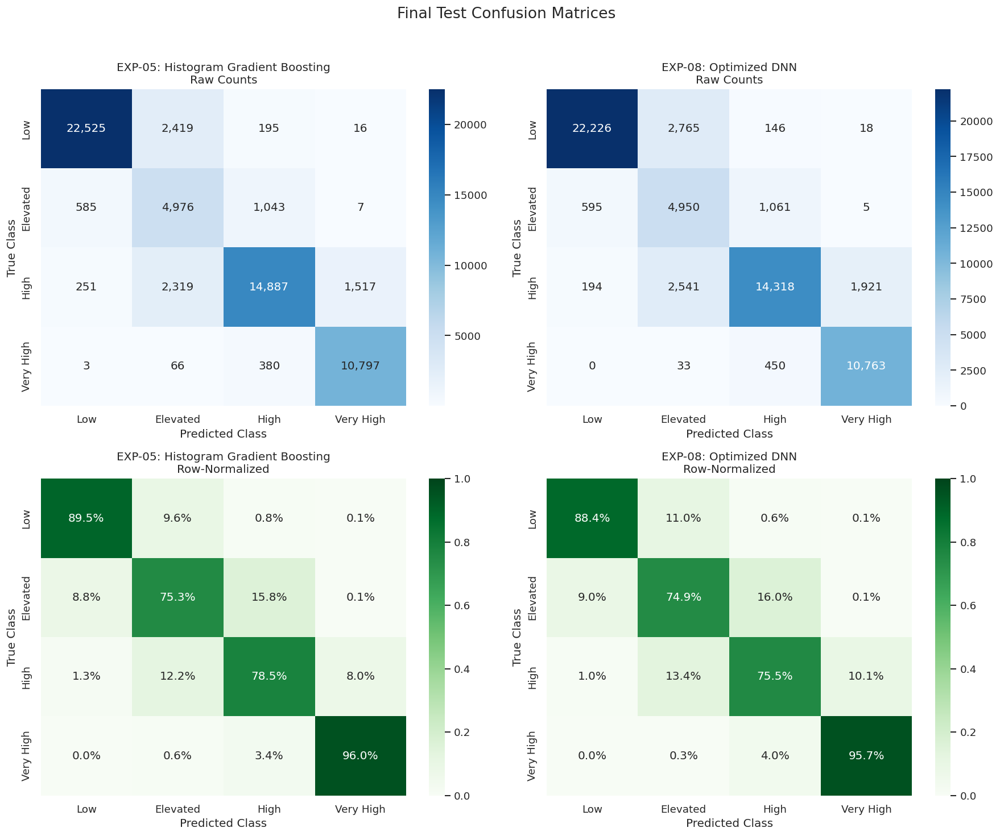

Figure saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/results/figures/final_test_confusion_matrices.png


In [ ]:
# Final Test Confusion Matrices


from sklearn.metrics import confusion_matrix

label_ids = sorted(class_labels)
display_labels = [
    class_labels[class_id]
    for class_id in label_ids
]

model_predictions = {
    "EXP-05: Histogram Gradient Boosting":
        y_test_pred_traditional,
    "EXP-08: Optimized DNN":
        y_test_pred_deep,
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 12),
)

for column_index, (model_name, predictions) in enumerate(
    model_predictions.items()
):
    # Raw-count confusion matrix
    raw_matrix = confusion_matrix(
        y_test_array,
        predictions,
        labels=label_ids,
    )

    sns.heatmap(
        raw_matrix,
        annot=True,
        fmt=",d",
        cmap="Blues",
        xticklabels=display_labels,
        yticklabels=display_labels,
        ax=axes[0, column_index],
    )

    axes[0, column_index].set_title(
        f"{model_name}\nRaw Counts"
    )
    axes[0, column_index].set_xlabel("Predicted Class")
    axes[0, column_index].set_ylabel("True Class")

    # Row-normalized confusion matrix
    normalized_matrix = confusion_matrix(
        y_test_array,
        predictions,
        labels=label_ids,
        normalize="true",
    )

    sns.heatmap(
        normalized_matrix,
        annot=True,
        fmt=".1%",
        cmap="Greens",
        vmin=0,
        vmax=1,
        xticklabels=display_labels,
        yticklabels=display_labels,
        ax=axes[1, column_index],
    )

    axes[1, column_index].set_title(
        f"{model_name}\nRow-Normalized"
    )
    axes[1, column_index].set_xlabel("Predicted Class")
    axes[1, column_index].set_ylabel("True Class")

plt.suptitle(
    "Final Test Confusion Matrices",
    fontsize=16,
    y=1.02,
)

plt.tight_layout()

confusion_matrix_path = (
    FIGURES_DIR / "final_test_confusion_matrices.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved to: {confusion_matrix_path}")

## 18. ROC and Precision–Recall Analysis

One-vs-rest ROC curves measure each model's ability to rank one class against all remaining classes. Precision–recall curves provide a stricter view of performance for less frequent classes. Both analyses are important because high overall accuracy can conceal weak minority-class performance.

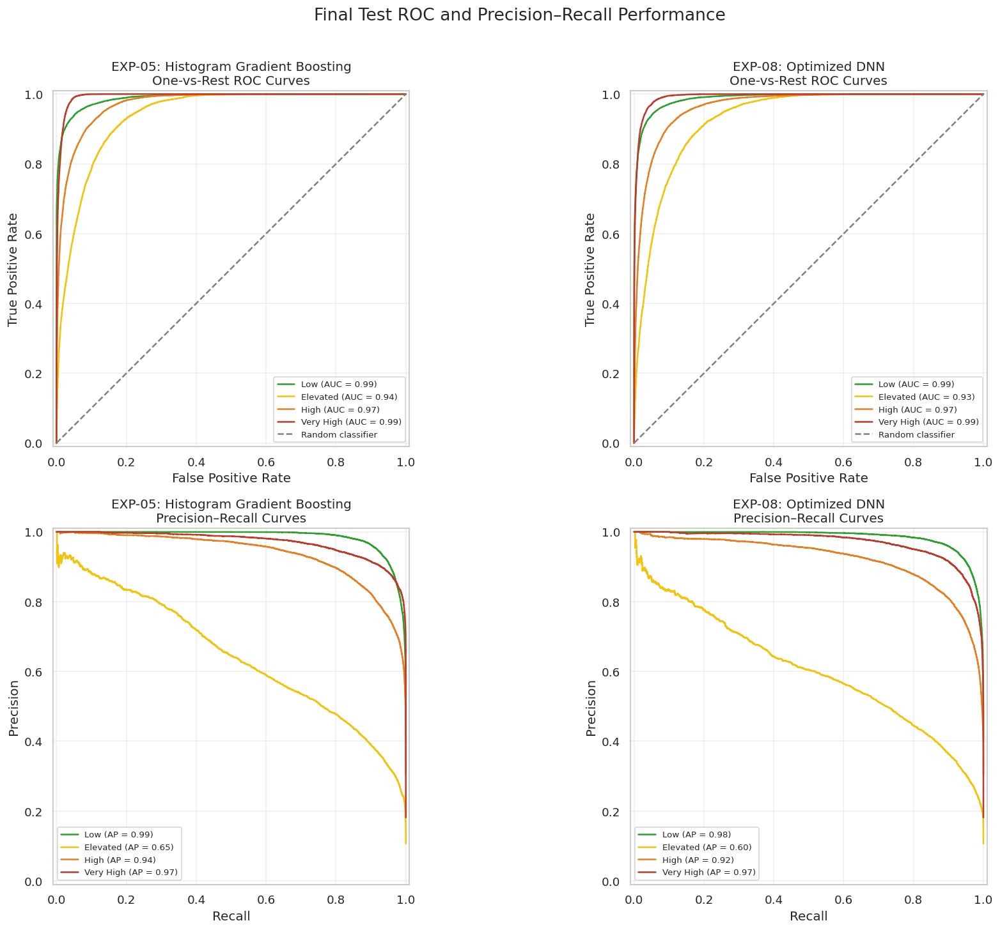

Figure saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/results/figures/final_test_roc_and_precision_recall_curves.png


In [ ]:
# Multiclass ROC and Precision-Recall Curves
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
)
from sklearn.preprocessing import label_binarize

# Convert the multiclass target into one-vs-rest binary columns
y_test_binary = label_binarize(
    y_test_array,
    classes=label_ids,
)

# Probability predictions from the two selected models
probability_sets = {
    "EXP-05: Histogram Gradient Boosting":
        y_test_prob_traditional,

    "EXP-08: Optimized DNN":
        y_test_prob_deep,
}

curve_colors = [
    "#2ca02c",  # Low
    "#f1c40f",  # Elevated
    "#e67e22",  # High
    "#c0392b",  # Very High
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(16, 12),
)

for model_index, (model_name, probabilities) in enumerate(
    probability_sets.items()
):
    roc_axis = axes[0, model_index]
    precision_recall_axis = axes[1, model_index]

    for class_id, class_name, color in zip(
        label_ids,
        display_labels,
        curve_colors,
    ):
        # One-vs-rest ROC curve
        RocCurveDisplay.from_predictions(
            y_test_binary[:, class_id],
            probabilities[:, class_id],
            name=class_name,
            color=color,
            ax=roc_axis,
        )

        # One-vs-rest precision-recall curve
        PrecisionRecallDisplay.from_predictions(
            y_test_binary[:, class_id],
            probabilities[:, class_id],
            name=class_name,
            color=color,
            ax=precision_recall_axis,
        )

    # Random-classifier reference line for the ROC plot
    roc_axis.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        linewidth=1.5,
        label="Random classifier",
    )

    roc_axis.set_title(
        f"{model_name}\nOne-vs-Rest ROC Curves"
    )
    roc_axis.set_xlabel("False Positive Rate")
    roc_axis.set_ylabel("True Positive Rate")
    roc_axis.legend(
        loc="lower right",
        fontsize=8,
    )
    roc_axis.grid(alpha=0.3)

    precision_recall_axis.set_title(
        f"{model_name}\nPrecision–Recall Curves"
    )
    precision_recall_axis.set_xlabel("Recall")
    precision_recall_axis.set_ylabel("Precision")
    precision_recall_axis.legend(
        loc="lower left",
        fontsize=8,
    )
    precision_recall_axis.grid(alpha=0.3)

fig.suptitle(
    "Final Test ROC and Precision–Recall Performance",
    fontsize=16,
    y=1.01,
)

plt.tight_layout()

# Ensure the output directory exists
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

curve_figure_path = (
    FIGURES_DIR
    / "final_test_roc_and_precision_recall_curves.png"
)

plt.savefig(
    curve_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved to: {curve_figure_path}")

## 19. Learning Curves and Bias–Variance Analysis

The traditional model is retrained using progressively larger chronological portions of the training set. Training and validation macro-F1 are compared to determine whether additional data improves generalization. For the optimized neural network, epoch-level accuracy and loss curves are examined to identify convergence and overfitting.

Generating chronological learning curve for EXP-05...
20% (57,651 rows) | Train Macro F1: 0.8778 | Validation Macro F1: 0.7343
40% (115,303 rows) | Train Macro F1: 0.8605 | Validation Macro F1: 0.7677
60% (172,954 rows) | Train Macro F1: 0.8433 | Validation Macro F1: 0.7884
80% (230,606 rows) | Train Macro F1: 0.8372 | Validation Macro F1: 0.7930
100% (288,258 rows) | Train Macro F1: 0.8382 | Validation Macro F1: 0.8041


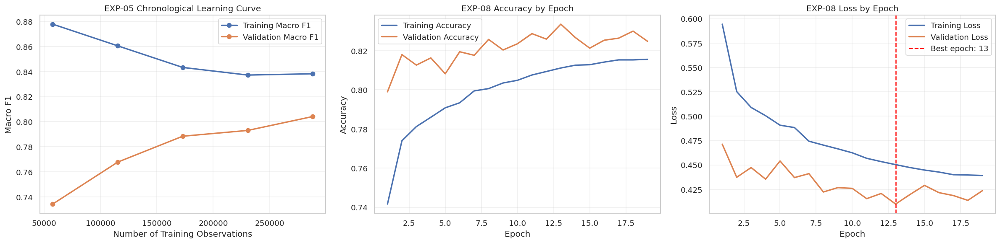


Figure saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/results/figures/traditional_and_deep_learning_curves.png


In [ ]:

#  Traditional and Deep-Learning Curves

from sklearn.base import clone
from sklearn.metrics import f1_score

training_fractions = [0.20, 0.40, 0.60, 0.80, 1.00]

learning_sample_sizes = []
traditional_train_f1 = []
traditional_val_f1 = []

print("Generating chronological learning curve for EXP-05...")

for fraction in training_fractions:
    sample_size = int(len(X_train) * fraction)

    # Use the earliest chronological portion of training data
    X_train_subset = X_train.iloc[:sample_size]
    y_train_subset = y_train.iloc[:sample_size]

    learning_curve_model = clone(best_traditional_model)

    learning_curve_model.fit(
        X_train_subset,
        y_train_subset,
    )

    subset_train_predictions = learning_curve_model.predict(
        X_train_subset
    )

    subset_val_predictions = learning_curve_model.predict(
        X_val
    )

    train_macro_f1 = f1_score(
        y_train_subset,
        subset_train_predictions,
        average="macro",
        zero_division=0,
    )

    val_macro_f1 = f1_score(
        y_val,
        subset_val_predictions,
        average="macro",
        zero_division=0,
    )

    learning_sample_sizes.append(sample_size)
    traditional_train_f1.append(train_macro_f1)
    traditional_val_f1.append(val_macro_f1)

    print(
        f"{fraction:.0%} ({sample_size:,} rows) | "
        f"Train Macro F1: {train_macro_f1:.4f} | "
        f"Validation Macro F1: {val_macro_f1:.4f}"
    )

# EXP-08 epoch history
exp08_history = training_histories["EXP-08"].history
exp08_epochs = range(1, len(exp08_history["loss"]) + 1)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 5),
)

# Traditional learning curve
axes[0].plot(
    learning_sample_sizes,
    traditional_train_f1,
    marker="o",
    linewidth=2,
    label="Training Macro F1",
)

axes[0].plot(
    learning_sample_sizes,
    traditional_val_f1,
    marker="o",
    linewidth=2,
    label="Validation Macro F1",
)

axes[0].set_title("EXP-05 Chronological Learning Curve")
axes[0].set_xlabel("Number of Training Observations")
axes[0].set_ylabel("Macro F1")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Deep-learning accuracy curve
axes[1].plot(
    exp08_epochs,
    exp08_history["accuracy"],
    linewidth=2,
    label="Training Accuracy",
)

axes[1].plot(
    exp08_epochs,
    exp08_history["val_accuracy"],
    linewidth=2,
    label="Validation Accuracy",
)

axes[1].set_title("EXP-08 Accuracy by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Deep-learning loss curve
axes[2].plot(
    exp08_epochs,
    exp08_history["loss"],
    linewidth=2,
    label="Training Loss",
)

axes[2].plot(
    exp08_epochs,
    exp08_history["val_loss"],
    linewidth=2,
    label="Validation Loss",
)

best_epoch = (
    np.argmin(exp08_history["val_loss"]) + 1
)

axes[2].axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best epoch: {best_epoch}",
)

axes[2].set_title("EXP-08 Loss by Epoch")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()

learning_curve_path = (
    FIGURES_DIR / "traditional_and_deep_learning_curves.png"
)

plt.savefig(
    learning_curve_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"\nFigure saved to: {learning_curve_path}")

## 20. Feature Importance

Permutation importance measures the reduction in validation macro-F1 when each predictor is randomly shuffled. A large reduction indicates that the trained Histogram Gradient Boosting model relies strongly on that feature. Importance is calculated on a reproducible validation sample to reduce computation time and avoid using the final test set for further analysis.

Calculating permutation importance using 15,000 validation observations...


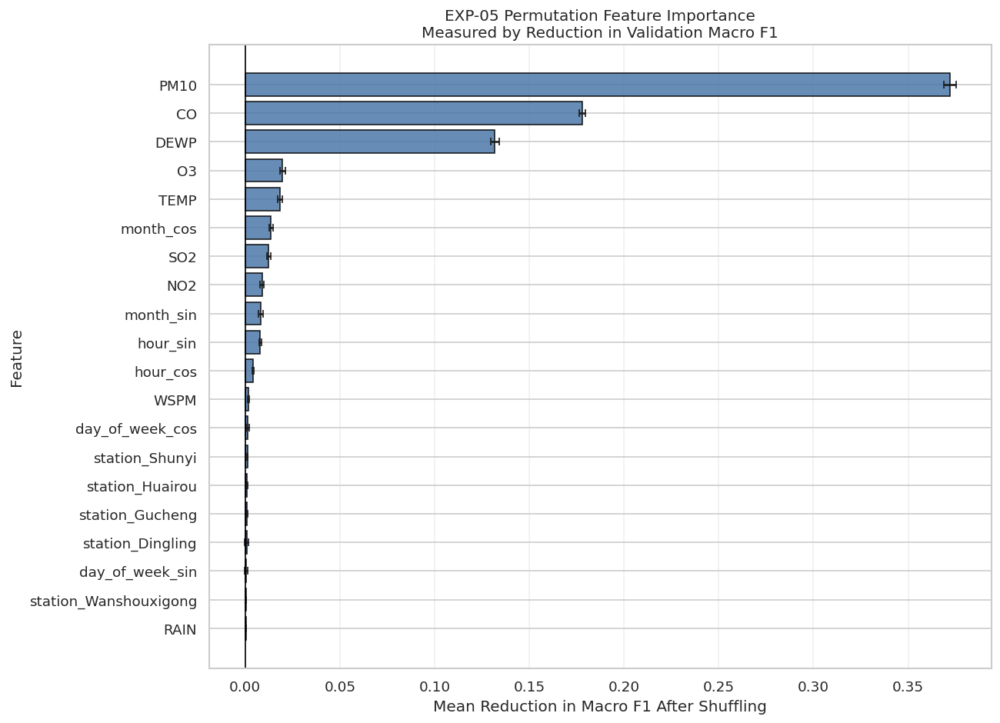

Calculation completed in 7.37 seconds.
Results saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/results/exp05_permutation_feature_importance.csv
Figure saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/results/figures/exp05_permutation_feature_importance.png


,Feature,Importance Mean,Importance Standard Deviation
0,PM10,0.372032,0.003180
1,CO,0.177990,0.001514
2,DEWP,0.131844,0.002099
3,O3,0.019755,0.001342
4,TEMP,0.018482,0.001203
5,month_cos,0.013687,0.001074
6,SO2,0.012475,0.000908
7,NO2,0.008894,0.000981
8,month_sin,0.008181,0.001291
9,hour_sin,0.007862,0.000645


In [ ]:

#  Permutation Feature Importance for EXP-05

from sklearn.inspection import permutation_importance

# Use a reproducible validation sample for efficient computation
importance_sample_size = min(15_000, len(X_val))

importance_sample_indices = X_val.sample(
    n=importance_sample_size,
    random_state=SEED,
).index

X_importance = X_val.loc[importance_sample_indices]
y_importance = y_val.loc[importance_sample_indices]

print(
    "Calculating permutation importance using "
    f"{importance_sample_size:,} validation observations..."
)

start_time = time.perf_counter()

permutation_results = permutation_importance(
    estimator=best_traditional_model,
    X=X_importance,
    y=y_importance,
    scoring="f1_macro",
    n_repeats=5,
    random_state=SEED,
    n_jobs=-1,
)

importance_time = time.perf_counter() - start_time

feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance Mean": permutation_results.importances_mean,
    "Importance Standard Deviation":
        permutation_results.importances_std,
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance Mean",
    ascending=False,
).reset_index(drop=True)

# Save all feature-importance values
feature_importance_path = (
    RESULTS_DIR / "exp05_permutation_feature_importance.csv"
)

feature_importance_df.to_csv(
    feature_importance_path,
    index=False,
)

# Plot the 20 most important predictors
top_feature_count = 20

top_features = (
    feature_importance_df
    .head(top_feature_count)
    .sort_values(
        by="Importance Mean",
        ascending=True,
    )
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Standard Deviation"],
    color="#4c78a8",
    edgecolor="black",
    alpha=0.85,
    capsize=3,
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    "EXP-05 Permutation Feature Importance\n"
    "Measured by Reduction in Validation Macro F1"
)
plt.xlabel("Mean Reduction in Macro F1 After Shuffling")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

feature_importance_figure_path = (
    FIGURES_DIR / "exp05_permutation_feature_importance.png"
)

plt.savefig(
    feature_importance_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Calculation completed in {importance_time:.2f} seconds."
)
print(f"Results saved to: {feature_importance_path}")
print(f"Figure saved to: {feature_importance_figure_path}")

display(feature_importance_df.head(20).round(6))

## 21. Boundary-Based Error Analysis

Because the target classes are created using fixed PM2.5 thresholds, observations close to a threshold may be inherently difficult to classify from related pollutants and weather measurements. This analysis measures each test observation's distance from the nearest class boundary and compares misclassification rates at increasing distances.

,Boundary Distance Group,Observations,EXP05_Accuracy,EXP08_Accuracy,Mean_Distance,EXP-05 Error Rate,EXP-08 Error Rate
0,0–2,3114,58.73%,50.16%,1.00,41.27%,49.84%
1,2–5,4789,65.30%,60.22%,3.50,34.70%,39.78%
2,5–10,8342,71.41%,69.68%,7.51,28.59%,30.32%
3,10–25,19667,88.20%,87.27%,18.13,11.80%,12.73%
4,25–50,19309,94.34%,93.95%,32.94,5.66%,6.05%
5,More than 50,6765,99.17%,98.95%,141.43,0.83%,1.05%


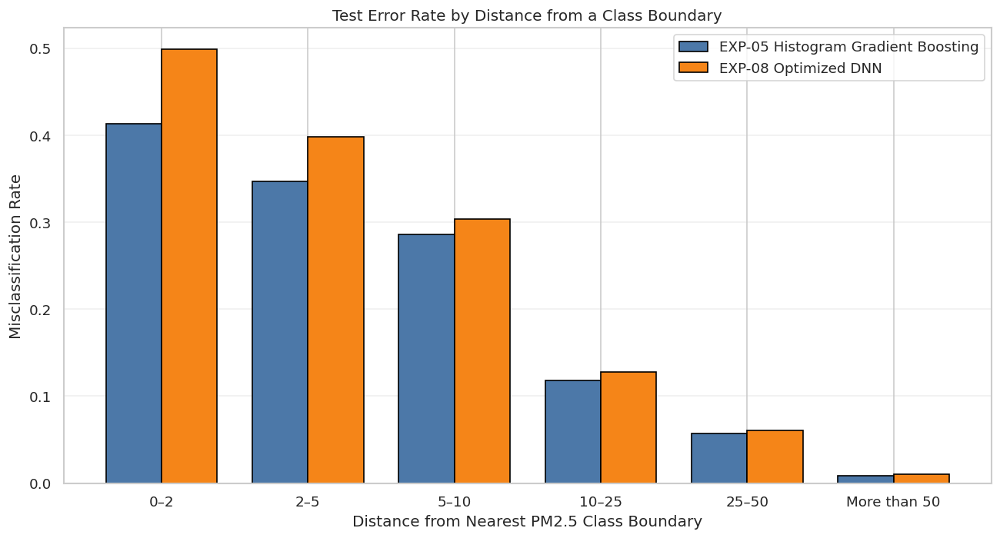

Summary saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/results/boundary_error_summary.csv
Detailed errors saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/results/test_prediction_error_details.csv


In [ ]:

# Classification-Boundary Error Analysis


# PM2.5 thresholds used to construct the four target classes
classification_boundaries = np.array(
    [35.4, 55.4, 150.4],
    dtype="float32",
)

# Preserve the chronological order used for test predictions
error_analysis_df = test_clean[
    [
        "datetime",
        "station",
        "PM2.5",
        "AirQualityClass",
    ]
].copy().reset_index(drop=True)

error_analysis_df["EXP-05 Prediction"] = (
    y_test_pred_traditional
)
error_analysis_df["EXP-08 Prediction"] = (
    y_test_pred_deep
)

error_analysis_df["EXP-05 Correct"] = (
    error_analysis_df["AirQualityClass"]
    == error_analysis_df["EXP-05 Prediction"]
)

error_analysis_df["EXP-08 Correct"] = (
    error_analysis_df["AirQualityClass"]
    == error_analysis_df["EXP-08 Prediction"]
)

# Calculate distance from the nearest class threshold
pm25_values = error_analysis_df["PM2.5"].to_numpy()

error_analysis_df["Distance to Nearest Boundary"] = np.min(
    np.abs(
        pm25_values[:, np.newaxis]
        - classification_boundaries[np.newaxis, :]
    ),
    axis=1,
)

# Group observations by distance from a threshold
distance_bins = [0, 2, 5, 10, 25, 50, np.inf]

distance_labels = [
    "0–2",
    "2–5",
    "5–10",
    "10–25",
    "25–50",
    "More than 50",
]

error_analysis_df["Boundary Distance Group"] = pd.cut(
    error_analysis_df["Distance to Nearest Boundary"],
    bins=distance_bins,
    labels=distance_labels,
    include_lowest=True,
    right=False,
)

boundary_error_summary = (
    error_analysis_df
    .groupby(
        "Boundary Distance Group",
        observed=False,
    )
    .agg(
        Observations=("PM2.5", "size"),
        EXP05_Accuracy=("EXP-05 Correct", "mean"),
        EXP08_Accuracy=("EXP-08 Correct", "mean"),
        Mean_Distance=(
            "Distance to Nearest Boundary",
            "mean",
        ),
    )
    .reset_index()
)

boundary_error_summary["EXP-05 Error Rate"] = (
    1 - boundary_error_summary["EXP05_Accuracy"]
)

boundary_error_summary["EXP-08 Error Rate"] = (
    1 - boundary_error_summary["EXP08_Accuracy"]
)

display(
    boundary_error_summary.style.format({
        "EXP05_Accuracy": "{:.2%}",
        "EXP08_Accuracy": "{:.2%}",
        "EXP-05 Error Rate": "{:.2%}",
        "EXP-08 Error Rate": "{:.2%}",
        "Mean_Distance": "{:.2f}",
    })
)

# Plot misclassification rate by distance from a threshold
plot_positions = np.arange(len(distance_labels))
bar_width = 0.38

plt.figure(figsize=(11, 6))

plt.bar(
    plot_positions - bar_width / 2,
    boundary_error_summary["EXP-05 Error Rate"],
    width=bar_width,
    label="EXP-05 Histogram Gradient Boosting",
    color="#4c78a8",
    edgecolor="black",
)

plt.bar(
    plot_positions + bar_width / 2,
    boundary_error_summary["EXP-08 Error Rate"],
    width=bar_width,
    label="EXP-08 Optimized DNN",
    color="#f58518",
    edgecolor="black",
)

plt.xticks(
    plot_positions,
    distance_labels,
)

plt.xlabel(
    "Distance from Nearest PM2.5 Class Boundary"
)
plt.ylabel("Misclassification Rate")
plt.title(
    "Test Error Rate by Distance from a Class Boundary"
)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

boundary_figure_path = (
    FIGURES_DIR / "boundary_distance_error_analysis.png"
)

plt.savefig(
    boundary_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Save the detailed and summarized results
boundary_summary_path = (
    RESULTS_DIR / "boundary_error_summary.csv"
)

detailed_error_path = (
    RESULTS_DIR / "test_prediction_error_details.csv"
)

boundary_error_summary.to_csv(
    boundary_summary_path,
    index=False,
)

error_analysis_df.to_csv(
    detailed_error_path,
    index=False,
)

print(f"Summary saved to: {boundary_summary_path}")
print(f"Detailed errors saved to: {detailed_error_path}")

## 22. Save Models and Reproducibility Artifacts

The best traditional and deep-learning models are saved alongside the scaler, training-derived imputation values, encoded feature order, target labels, and class thresholds. These artifacts allow future observations to be processed consistently with the training data.

In [ ]:

#  Save Final Models and Preprocessing Artifacts

import platform
import sklearn

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# File paths
traditional_model_path = (
    MODEL_DIR / "best_traditional_model_exp05.joblib"
)

deep_model_path = (
    MODEL_DIR / "best_deep_model_exp08.keras"
)

preprocessing_path = (
    MODEL_DIR / "preprocessing_artifacts.joblib"
)

manifest_path = (
    MODEL_DIR / "model_manifest.json"
)

# Save the selected traditional model
joblib.dump(
    best_traditional_model,
    traditional_model_path,
)

# Save the selected Keras model
best_deep_model.save(
    deep_model_path,
)

# Save everything required to reproduce preprocessing
preprocessing_artifacts = {
    "scaler": scaler,
    "feature_columns": X_train.columns.tolist(),
    "sensor_columns": sensor_columns,
    "training_global_medians":
        training_global_medians.to_dict(),
    "training_station_medians":
        training_station_medians.to_dict(),
    "training_station_wind_modes":
        training_station_wind_modes.to_dict(),
    "training_global_wind_mode":
        training_global_wind_mode,
    "class_labels": class_labels,
    "classification_boundaries":
        classification_boundaries.tolist(),
    "categorical_columns": ["station", "wd"],
    "target_column": "AirQualityClass",
    "excluded_predictor": "PM2.5",
    "random_seed": SEED,
    "split_method": "chronological",
    "train_end": str(train_df["datetime"].max()),
    "validation_start": str(val_df["datetime"].min()),
    "validation_end": str(val_df["datetime"].max()),
    "test_start": str(test_df["datetime"].min()),
    "test_end": str(test_df["datetime"].max()),
}

joblib.dump(
    preprocessing_artifacts,
    preprocessing_path,
)

# Create a human-readable model manifest
model_manifest = {
    "project": "Beijing Air Quality Classification",
    "selected_traditional_model": {
        "experiment_id": "EXP-05",
        "name": "Histogram Gradient Boosting",
        "file": traditional_model_path.name,
        "test_macro_f1": round(
            float(
                final_test_results.loc[
                    final_test_results["Experiment ID"]
                    == "EXP-05",
                    "Macro F1",
                ].iloc[0]
            ),
            4,
        ),
    },
    "selected_deep_model": {
        "experiment_id": "EXP-08",
        "name": "Optimized DNN with LR Scheduling",
        "file": deep_model_path.name,
        "test_macro_f1": round(
            float(
                final_test_results.loc[
                    final_test_results["Experiment ID"]
                    == "EXP-08",
                    "Macro F1",
                ].iloc[0]
            ),
            4,
        ),
    },
    "preprocessing_file": preprocessing_path.name,
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "tensorflow_version": tf.__version__,
    "number_of_features": int(X_train.shape[1]),
    "class_labels": {
        str(key): value
        for key, value in class_labels.items()
    },
}

with open(
    manifest_path,
    "w",
    encoding="utf-8",
) as manifest_file:
    json.dump(
        model_manifest,
        manifest_file,
        indent=2,
    )

# Verify that every artifact exists
saved_artifacts = [
    traditional_model_path,
    deep_model_path,
    preprocessing_path,
    manifest_path,
]

print("Saved model artifacts:\n")

for artifact in saved_artifacts:
    file_size_mb = artifact.stat().st_size / (1024 ** 2)

    print(
        f"{artifact.name}: "
        f"{file_size_mb:.2f} MB"
    )

print(f"\nAll model files saved to: {MODEL_DIR}")

Saved model artifacts:

best_traditional_model_exp05.joblib: 2.78 MB
best_deep_model_exp08.keras: 0.69 MB
preprocessing_artifacts.joblib: 0.01 MB
model_manifest.json: 0.00 MB

All model files saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/models


## 23. Artifact Verification and Reproducibility

The saved models and preprocessing artifacts are reloaded from disk and tested on a sample of unseen observations. Matching predictions confirm that the exported files are valid. Exact library versions are also recorded in `requirements.txt` to support reproducibility.

In [ ]:

# Verify Saved Artifacts and Create requirements.txt


# Reload saved artifacts
reloaded_traditional_model = joblib.load(
    traditional_model_path
)

reloaded_preprocessing = joblib.load(
    preprocessing_path
)

reloaded_deep_model = tf.keras.models.load_model(
    deep_model_path
)

# Test reloaded models on the first 100 test observations
verification_size = 100

reloaded_traditional_predictions = (
    reloaded_traditional_model.predict(
        X_test.iloc[:verification_size]
    )
)

reloaded_deep_probabilities = (
    reloaded_deep_model.predict(
        X_test_scaled[:verification_size],
        verbose=0,
    )
)

reloaded_deep_predictions = np.argmax(
    reloaded_deep_probabilities,
    axis=1,
)

# Confirm predictions match those produced before saving
assert np.array_equal(
    reloaded_traditional_predictions,
    y_test_pred_traditional[:verification_size],
)

assert np.array_equal(
    reloaded_deep_predictions,
    y_test_pred_deep[:verification_size],
)

assert (
    reloaded_preprocessing["feature_columns"]
    == X_train.columns.tolist()
)

print("Traditional model reload test: PASSED")
print("Deep-learning model reload test: PASSED")
print("Preprocessing artifact test: PASSED")

# Create a version-pinned requirements file
requirements_path = PROJECT_DIR / "requirements.txt"

requirements_content = f"""numpy=={np.__version__}
pandas=={pd.__version__}
matplotlib=={plt.matplotlib.__version__}
seaborn=={sns.__version__}
scikit-learn=={sklearn.__version__}
tensorflow=={tf.__version__}
joblib=={joblib.__version__}
jupyter
"""

requirements_path.write_text(
    requirements_content,
    encoding="utf-8",
)

print(f"\nRequirements saved to: {requirements_path}")

# Verify important project outputs
required_outputs = [
    results_csv_path,
    final_results_path,
    traditional_report_path,
    deep_report_path,
    confusion_matrix_path,
    curve_figure_path,
    learning_curve_path,
    feature_importance_path,
    feature_importance_figure_path,
    boundary_summary_path,
    detailed_error_path,
    boundary_figure_path,
    traditional_model_path,
    deep_model_path,
    preprocessing_path,
    manifest_path,
    requirements_path,
]

artifact_check = pd.DataFrame({
    "Artifact": [
        str(path.relative_to(PROJECT_DIR))
        for path in required_outputs
    ],
    "Exists": [
        path.exists()
        for path in required_outputs
    ],
    "Size (MB)": [
        round(path.stat().st_size / (1024 ** 2), 3)
        if path.exists()
        else 0
        for path in required_outputs
    ],
})

display(artifact_check)

assert artifact_check["Exists"].all()

print("\nAll required notebook artifacts were verified successfully.")
print("The modeling and evaluation notebook is complete.")

Traditional model reload test: PASSED
Deep-learning model reload test: PASSED
Preprocessing artifact test: PASSED

Requirements saved to: /content/drive/MyDrive/ML_Final_Project_Beijing_Air_Quality/requirements.txt


,Artifact,Exists,Size (MB)
0,results/experiment_results.csv,True,0.004
1,results/final_test_results.csv,True,0.000
2,results/exp05_test_classification_report.csv,True,0.001
3,results/exp08_test_classification_report.csv,True,0.001
4,results/figures/final_test_confusion_matrices.png,True,0.523
5,results/figures/final_test_roc_and_precision_r...,True,0.543
6,results/figures/traditional_and_deep_learning_...,True,0.401
7,results/exp05_permutation_feature_importance.csv,True,0.003
8,results/figures/exp05_permutation_feature_impo...,True,0.215
9,results/boundary_error_summary.csv,True,0.001



All required notebook artifacts were verified successfully.
The modeling and evaluation notebook is complete.


## 24. Conclusion

In this project, I compared traditional machine-learning models with deep-learning models to classify Beijing’s hourly air-quality measurements into four PM2.5 severity groups. I completed eight experiments and divided the data chronologically into training, validation, and test sets. This approach allowed me to evaluate how well the models could perform on later, unseen observations.

The Histogram Gradient Boosting model achieved the best test results, with an accuracy of 0.8580, a macro-F1 score of 0.8226, and a macro ROC-AUC of 0.9731. The optimized deep neural network also performed well, achieving an accuracy of 0.8430, a macro-F1 score of 0.8067, and a macro ROC-AUC of 0.9689. Although the neural network was competitive, Histogram Gradient Boosting performed slightly better and required less training time.

The feature-importance analysis showed that PM10, CO, and dew point contributed the most to the traditional model’s predictions. Both final models found the Elevated class more difficult to identify than the other classes. My error analysis showed that this difficulty was strongly related to the class boundaries. For the Histogram Gradient Boosting model, the error rate was 41.27% when PM2.5 was within two units of a boundary, compared with only 0.83% when it was more than 50 units away. This suggests that many incorrect predictions involved borderline observations rather than completely different air-quality conditions.

The learning curve showed that validation performance improved as more training data was introduced. At the same time, the gap between training and validation performance became smaller. This indicates that the final traditional model did not suffer from severe overfitting and could potentially benefit from additional representative data.

There are several limitations to this project. The four severity groups were created by combining PM2.5 concentration ranges, so they do not represent the complete official AQI classification system. The hourly observations from the same monitoring stations are also related over time and cannot be considered fully independent. Missing sensor readings required imputation, and changes in pollution patterns over time affected the class distributions. In addition, results obtained from Beijing monitoring stations may not generalize to cities with different climates, pollution sources, or monitoring systems.

In future work, I would explore models designed specifically for ordered classes and time-series data. I would also investigate probability calibration, alternative class thresholds, and loss functions that give special attention to observations near category boundaries. Finally, I would extend the project from classifying current air quality to forecasting future air-quality conditions, since advance predictions could provide greater practical value for public-health planning and early warnings.